# Proyecto Final IA 1 (Grupo C2 2026-2): Predicción Temprana de Riesgo de Accidentes Cerebrovasculares (ACV) (Grupo 3)

## Planteamiento del Problema y Motivación
* **Relevancia clínica:** Los accidentes cerebrovasculares (ACV) constituyen una de las principales causas de mortalidad y discapacidad permanente a nivel mundial. Un sistema de triaje preventivo basado en variables clínicas y demográficas rutinarias permite identificar pacientes de alto riesgo antes de un evento crítico.
* **Desafíos técnicos del problema:**
  1. **Desbalance severo de clases:** Apenas el $4.87\%$ de los registros corresponden a eventos positivos de ACV, invalidando métricas tradicionales como el *Accuracy*.
  2. **Asimetría y valores faltantes:** Variables biomédicas clave como `avg_glucose_level` y `bmi` presentan fuertes sesgos positivos y datos incompletos que requieren imputación no paramétrica sin fuga de datos (*data leakage*).
  3. **Heterogeneidad de factores de riesgo:** Coexistencia de pacientes geriátricos metabólicos típicos y pacientes jóvenes con ACV atípicos.
* **Objetivos:** Construir y validar un flujo completo de ciencia de datos (EDA, Aprendizaje Supervisado y Aprendizaje No Supervisado) maximizando la **Sensibilidad (*Recall*)** y el **ROC-AUC** para minimizar los Falsos Negativos médicos.

---



# Parte 1: Análisis Exploratorio de Datos (`exploratory_data_analysis`)

## 1 Origen, Estructura y Definición del Problema
* **Fuente:** *Healthcare Dataset Stroke Data* ($5,110$ registros iniciales, $12$ columnas).
* **Tipo de problema:** Clasificación binaria supervisada.
* **Características ($X$):** $10$ variables predictoras tras descartar `id` (`age`, `gender`, `hypertension`, `heart_disease`, `ever_married`, `work_type`, `Residence_type`, `avg_glucose_level`, `bmi`, `smoking_status`).
* **Etiqueta objetivo ($y$):** Variable binaria `stroke` ($0 =$ No ACV, $1 =$ Sí ACV).

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Cargar el archivo csv desde GitHub
url = 'https://raw.githubusercontent.com/CarrlosP/Proyect_IA/refs/heads/main/healthcare-dataset-stroke-data.csv'
df = pd.read_csv(url)


# Configuración visual general
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 10})

print("Librerías cargadas correctamente.")

df.head()

Librerías cargadas correctamente.


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [ ]:
# Inspección básica
print(f"Dimensiones del dataset: {df.shape[0]} filas y {df.shape[1]} columnas.")
print("\n--- Información de Tipos de Datos y Nulos ---")
print(df.info())

# Limpieza inicial requerida
# 1. Eliminar ID por no aportar valor predictivo
if 'id' in df.columns:
    df = df.drop(columns=['id'])

# 2. Filtrar el registro aislado de gender == 'Other'
df = df[df['gender'] != 'Other']

print(f"\nDimensiones tras limpieza inicial: {df.shape}")
df.head()

Dimensiones del dataset: 5110 filas y 12 columnas.

--- Información de Tipos de Datos y Nulos ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB
None

Dimensiones tras limpieza inicial: (5109, 11)


,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


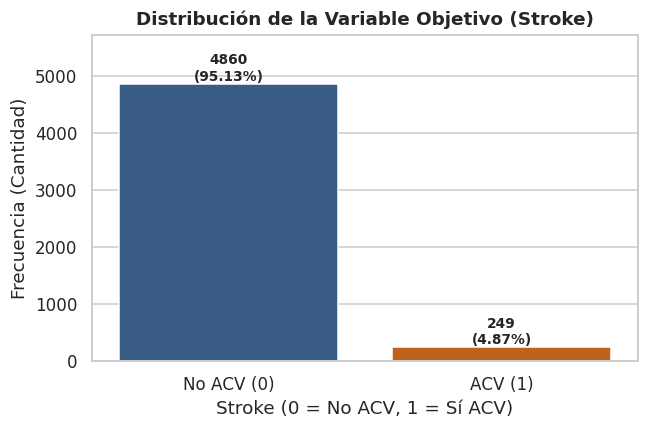

• No ACV (0): 4860 casos (95.13%)
• ACV (1): 249 casos (4.87%)


In [ ]:
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df, x='stroke', hue='stroke', palette=['#2b5c8f', '#d95f02'], legend=False)
total = len(df)
for p in ax.patches:
    height = p.get_height()
    percentage = f'{(height/total)*100:.2f}%'
    ax.annotate(f'{int(height)}\n({percentage})',
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom', fontweight='bold', fontsize=9)

plt.title('Distribución de la Variable Objetivo (Stroke)', fontweight='bold')
plt.xlabel('Stroke (0 = No ACV, 1 = Sí ACV)')
plt.ylabel('Frecuencia (Cantidad)')
plt.xticks(ticks=[0, 1], labels=['No ACV (0)', 'ACV (1)'])
plt.ylim(0, ax.get_ylim()[1] * 1.12)  # espacio extra arriba para que no se corte el texto
plt.tight_layout()
plt.show()

# Reporte en texto para la presentación
conteo_target = df['stroke'].value_counts()
porcentaje_target = df['stroke'].value_counts(normalize=True) * 100

print(f"• No ACV (0): {conteo_target[0]} casos ({porcentaje_target[0]:.2f}%)")
print(f"• ACV (1): {conteo_target[1]} casos ({porcentaje_target[1]:.2f}%)")

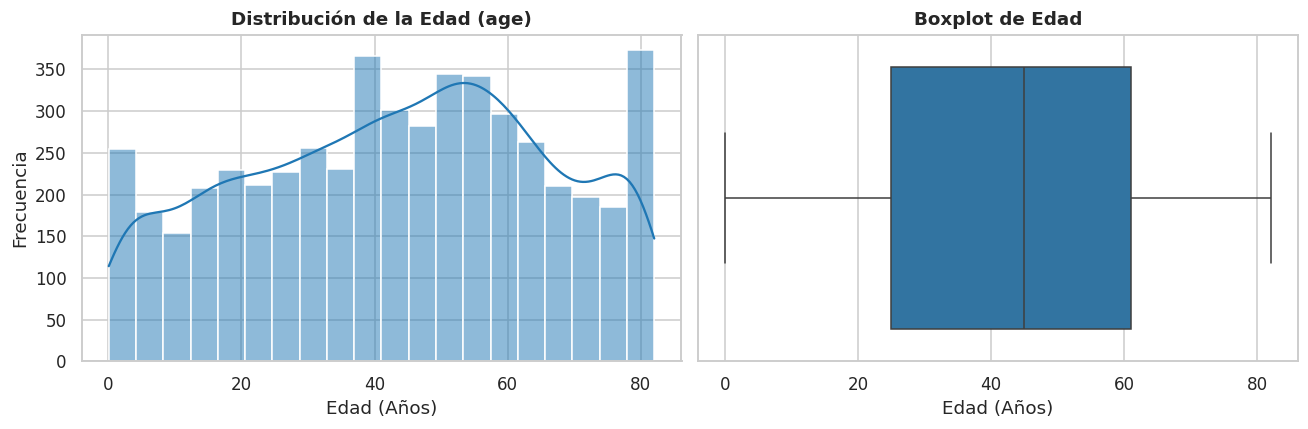

• 'La edad promedio de los pacientes es de 43.2 ± 22.6 años.'


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Histograma con curva KDE
sns.histplot(data=df, x='age', kde=True, color='#1f77b4', ax=axes[0])
axes[0].set_title('Distribución de la Edad (age)', fontweight='bold')
axes[0].set_xlabel('Edad (Años)')
axes[0].set_ylabel('Frecuencia')

# Boxplot
sns.boxplot(data=df, x='age', color='#1f77b4', ax=axes[1])
axes[1].set_title('Boxplot de Edad', fontweight='bold')
axes[1].set_xlabel('Edad (Años)')

plt.tight_layout()
plt.show()

# Cálculo de estadísticas simétricas
media_age = df['age'].mean()
std_age = df['age'].std()


print(f"• 'La edad promedio de los pacientes es de {media_age:.1f} ± {std_age:.1f} años.'")

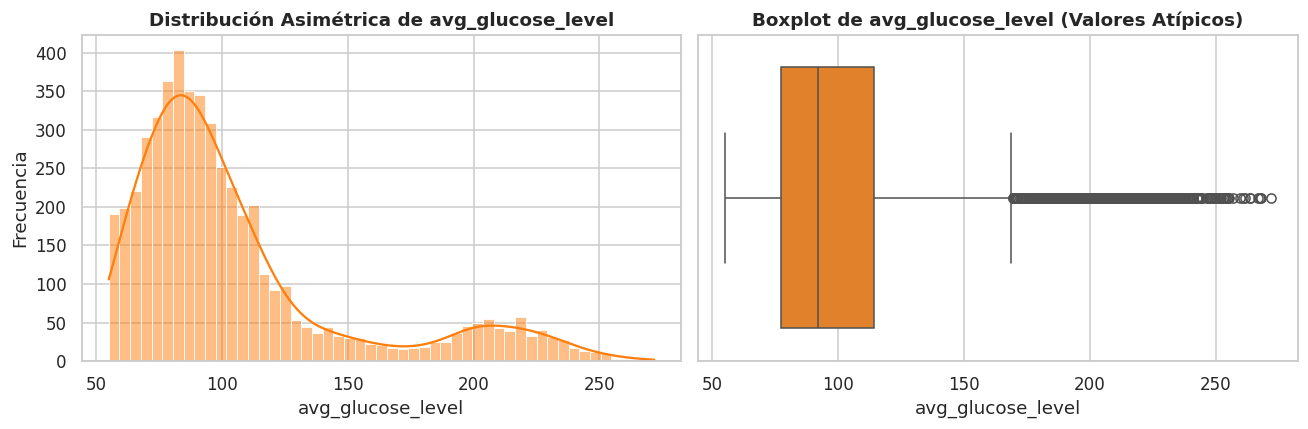

• Mediana: 91.88
• Rango Intercuartil (IQR): 36.85 (Q1: 77.24 - Q3: 114.09)
• Rango Total [Mín - Máx]: [55.12 - 271.74]



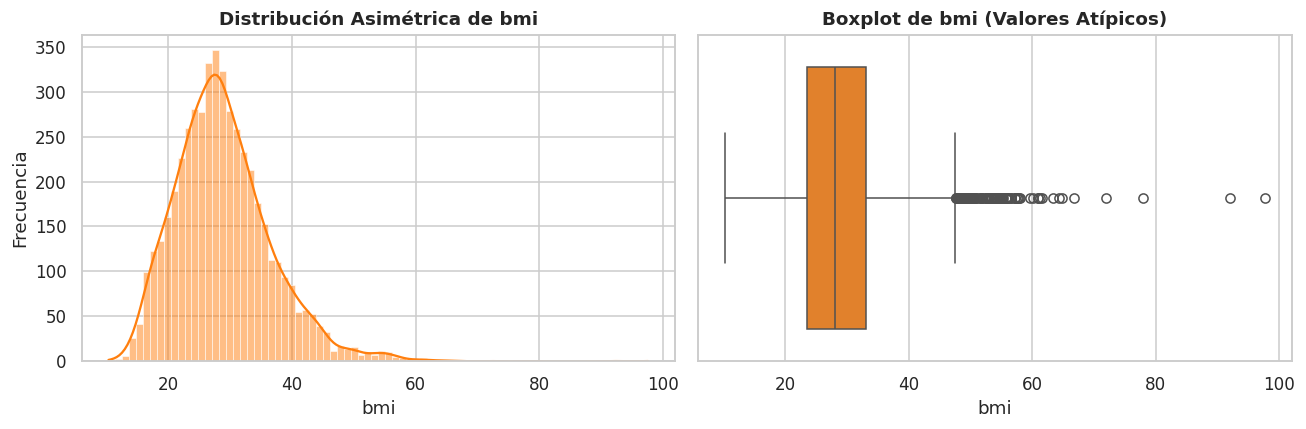

• Mediana: 28.10
• Rango Intercuartil (IQR): 9.60 (Q1: 23.50 - Q3: 33.10)
• Rango Total [Mín - Máx]: [10.30 - 97.60]



In [ ]:
vars_asimetricas = ['avg_glucose_level', 'bmi']

for var in vars_asimetricas:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    # Histograma
    sns.histplot(data=df, x=var, kde=True, color='#ff7f0e', ax=axes[0])
    axes[0].set_title(f'Distribución Asimétrica de {var}', fontweight='bold')
    axes[0].set_ylabel('Frecuencia')

    # Boxplot para visualizar atípicos
    sns.boxplot(data=df, x=var, color='#ff7f0e', ax=axes[1])
    axes[1].set_title(f'Boxplot de {var} (Valores Atípicos)', fontweight='bold')

    plt.tight_layout()
    plt.show()

    # Cálculo de estadísticas no paramétricas
    mediana = df[var].median()
    q1 = df[var].quantile(0.25)
    q3 = df[var].quantile(0.75)
    iqr = q3 - q1


    print(f"• Mediana: {mediana:.2f}")
    print(f"• Rango Intercuartil (IQR): {iqr:.2f} (Q1: {q1:.2f} - Q3: {q3:.2f})")
    print(f"• Rango Total [Mín - Máx]: [{df[var].min():.2f} - {df[var].max():.2f}]\n")

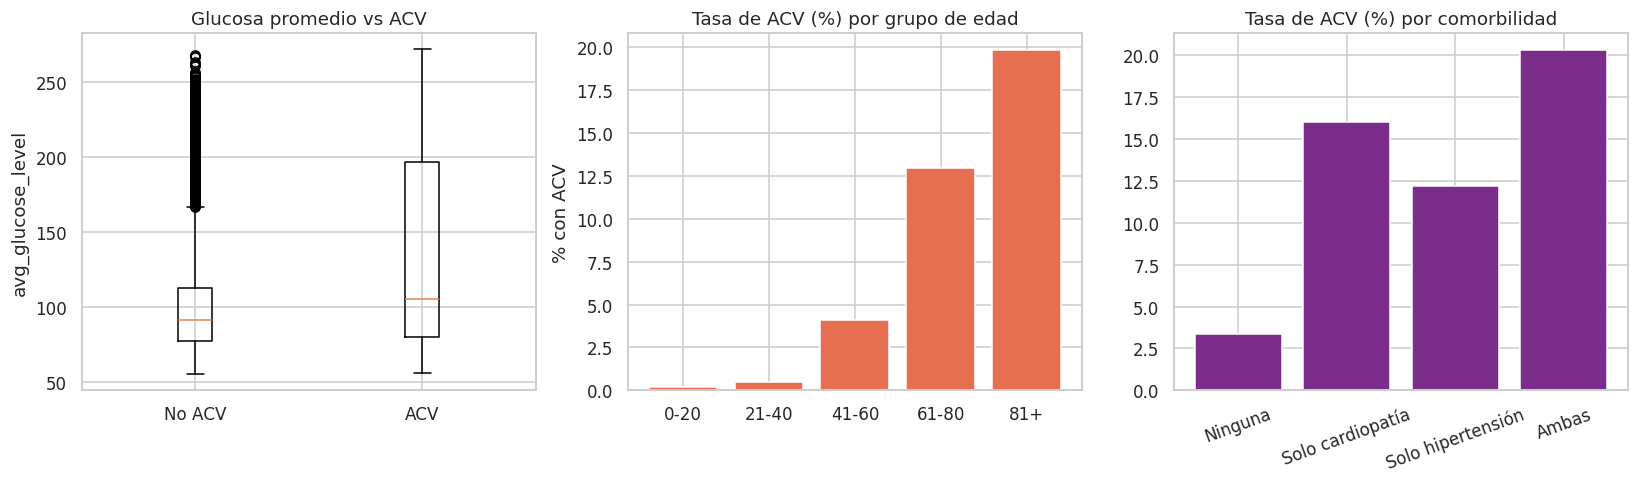

In [ ]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt


df['bmi'] = pd.to_numeric(df['bmi'], errors='coerce')

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# --- Panel 1: Glucosa promedio vs ACV (boxplot comparativo) ---
data0 = df[df.stroke == 0]['avg_glucose_level']
data1 = df[df.stroke == 1]['avg_glucose_level']
axes[0].boxplot([data0, data1], tick_labels=['No ACV', 'ACV'])
axes[0].set_title('Glucosa promedio vs ACV')
axes[0].set_ylabel('avg_glucose_level')

# --- Panel 2: Tasa de ACV (%) por grupo de edad ---
bins = [0, 20, 40, 60, 80, 100]
labels = ['0-20', '21-40', '41-60', '61-80', '81+']
df['age_group'] = pd.cut(df['age'], bins=bins, labels=labels)
tasa = df.groupby('age_group', observed=True)['stroke'].mean() * 100
axes[1].bar(tasa.index.astype(str), tasa.values, color='#E76F51')
axes[1].set_title('Tasa de ACV (%) por grupo de edad')
axes[1].set_ylabel('% con ACV')

# --- Panel 3: Tasa de ACV (%) por comorbilidad combinada ---
df['riesgo_comb'] = df['hypertension'].astype(str) + "-" + df['heart_disease'].astype(str)
tasa2 = df.groupby('riesgo_comb')['stroke'].mean() * 100
labels2 = {'0-0': 'Ninguna', '1-0': 'Solo hipertensión', '0-1': 'Solo cardiopatía', '1-1': 'Ambas'}
tasa2.index = [labels2.get(x, x) for x in tasa2.index]
axes[2].bar(tasa2.index, tasa2.values, color='#7B2D8B')
axes[2].set_title('Tasa de ACV (%) por comorbilidad')
axes[2].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.savefig('cruces_variables.png', dpi=130)
plt.show()

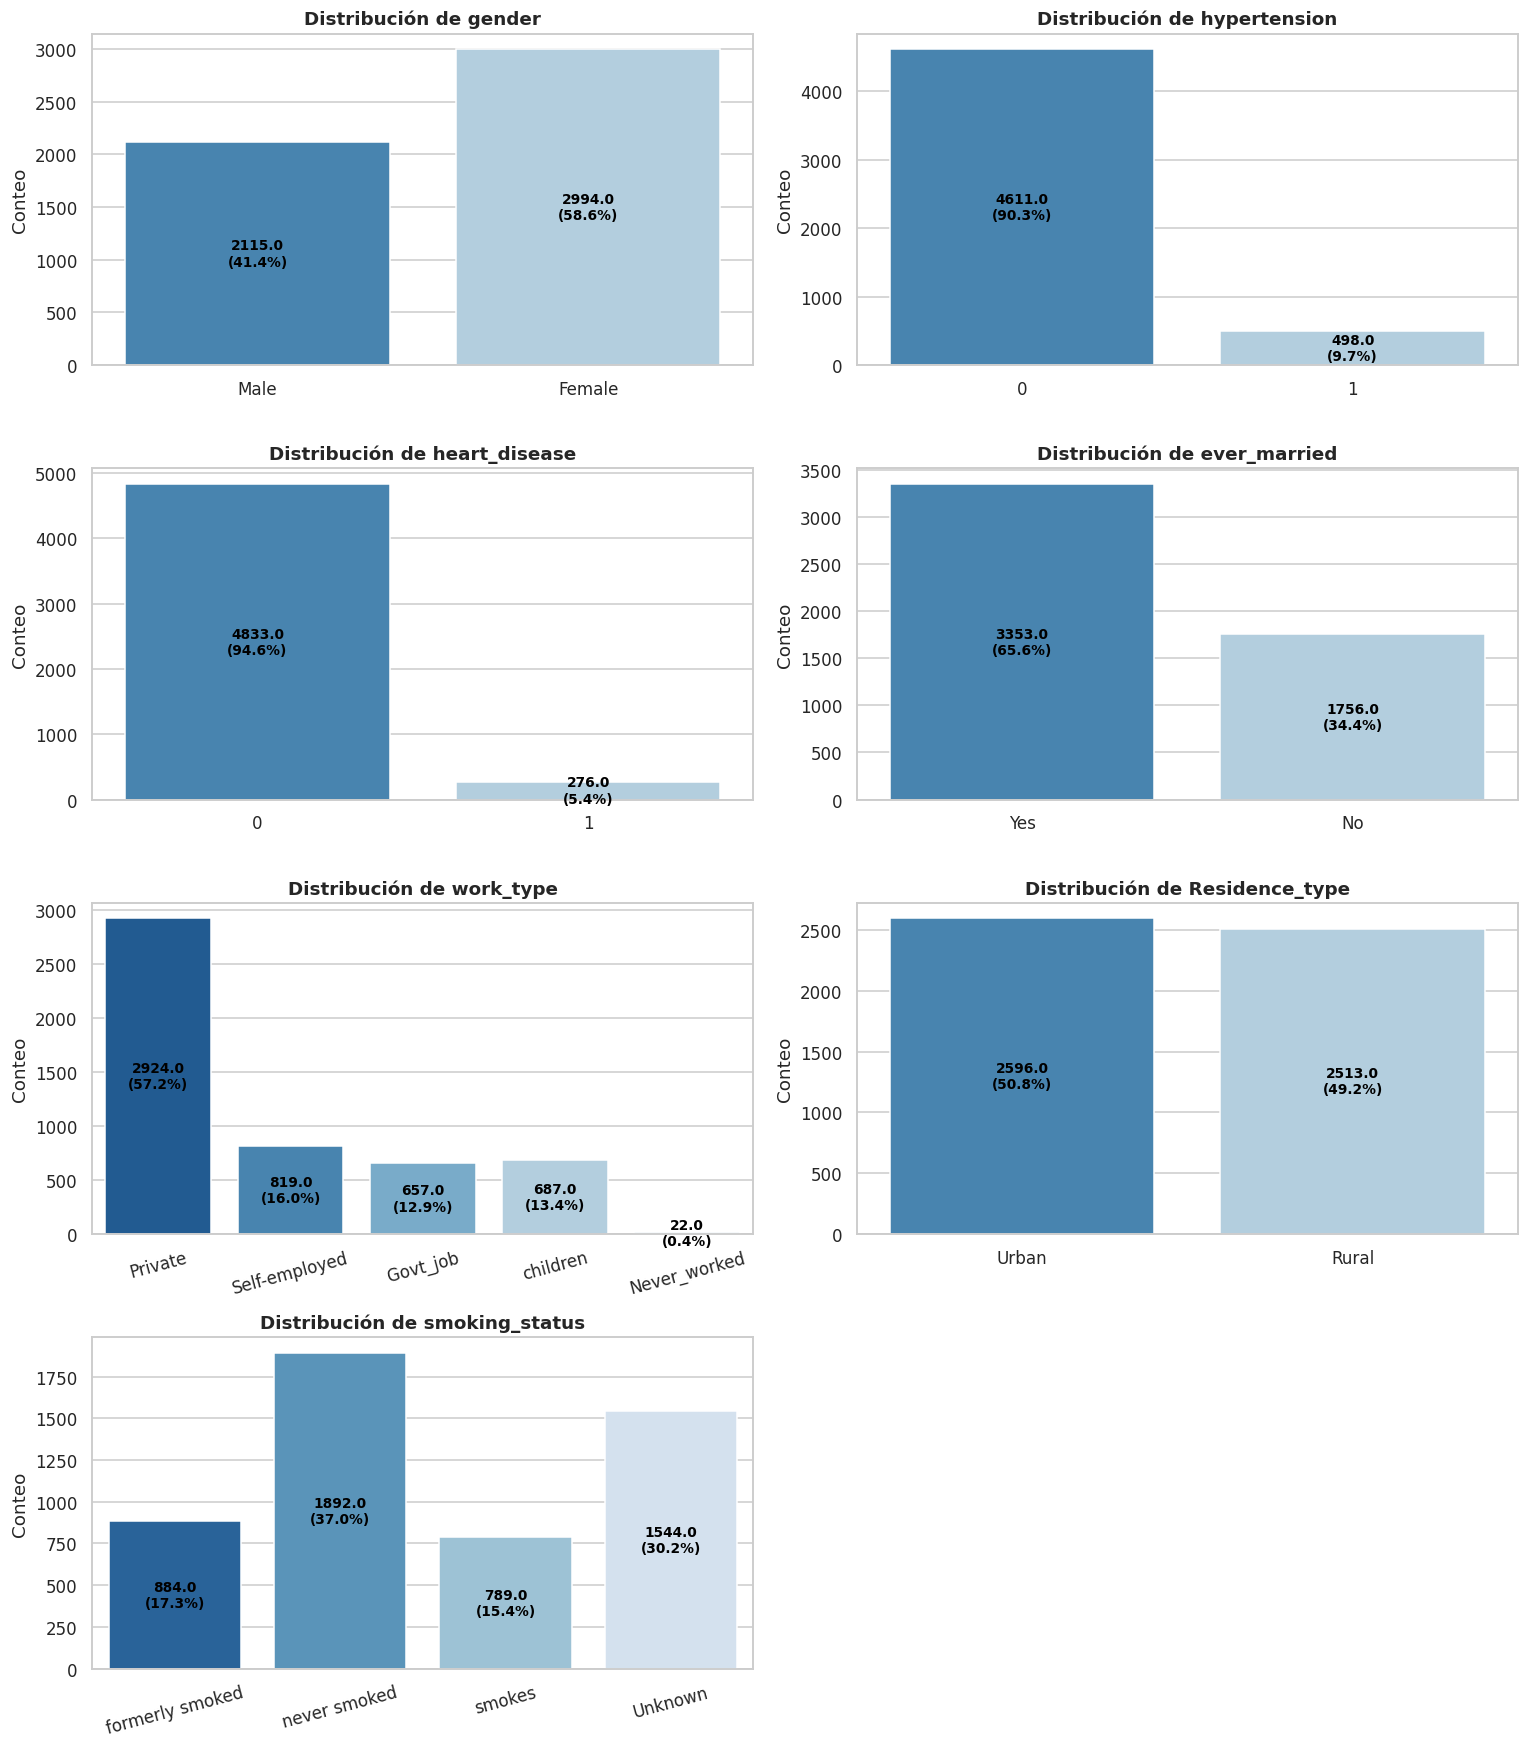


Variable: gender
        Frecuencia  Porcentaje (%)
gender                            
Female        2994            58.6
Male          2115            41.4

Variable: hypertension
              Frecuencia  Porcentaje (%)
hypertension                            
0                   4611           90.25
1                    498            9.75

Variable: heart_disease
               Frecuencia  Porcentaje (%)
heart_disease                            
0                    4833            94.6
1                     276             5.4

Variable: ever_married
              Frecuencia  Porcentaje (%)
ever_married                            
Yes                 3353           65.63
No                  1756           34.37

Variable: work_type
               Frecuencia  Porcentaje (%)
work_type                                
Private              2924           57.23
Self-employed         819           16.03
children              687           13.45
Govt_job              657           12.86


In [ ]:
cols_cat = ['gender', 'hypertension', 'heart_disease', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']

fig, axes = plt.subplots(nrows=4, ncols=2, figsize=(14, 16))
axes = axes.flatten()

for i, col in enumerate(cols_cat):
    sns.countplot(data=df, x=col, palette='Blues_r', ax=axes[i])
    axes[i].set_title(f'Distribución de {col}', fontweight='bold')
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Conteo')

    # Agregar porcentajes en las barras
    total_col = len(df[col].dropna())
    for p in axes[i].patches:
        height = p.get_height()
        porcentaje = (height / total_col) * 100
        axes[i].annotate(f'{height}\n({porcentaje:.1f}%)',
                         (p.get_x() + p.get_width() / 2., height / 2),
                         ha='center', va='center', color='black', fontsize=9, fontweight='bold')

    if col in ['work_type', 'smoking_status']:
        axes[i].tick_params(axis='x', rotation=15)

# Eliminar el subgráfico sobrente
fig.delaxes(axes[-1])

plt.tight_layout()
plt.show()

# Imprimir resumen categórico impreso
for col in cols_cat:
    print(f"\nVariable: {col}")
    resumen = pd.DataFrame({
        'Frecuencia': df[col].value_counts(),
        'Porcentaje (%)': (df[col].value_counts(normalize=True) * 100).round(2)
    })
    print(resumen)

--- ANÁLISIS DE VALORES NULOS ---
     Valores Faltantes  Porcentaje (%)
bmi                201        3.934234


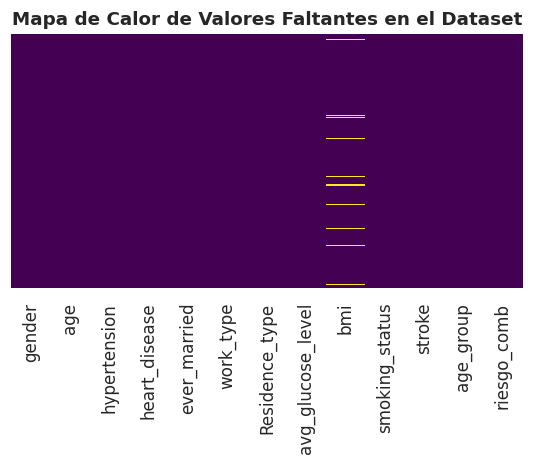

In [ ]:
# 1. Conteo y porcentaje de valores nulos
nulos = df.isnull().sum()
porcentaje_nulos = (df.isnull().sum() / len(df)) * 100

tabla_nulos = pd.DataFrame({'Valores Faltantes': nulos, 'Porcentaje (%)': porcentaje_nulos})
print("--- ANÁLISIS DE VALORES NULOS ---")
print(tabla_nulos[tabla_nulos['Valores Faltantes'] > 0])

# Visualización de la matriz de nulos
plt.figure(figsize=(6, 3))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis', yticklabels=False)
plt.title('Mapa de Calor de Valores Faltantes en el Dataset', fontweight='bold')
plt.show()

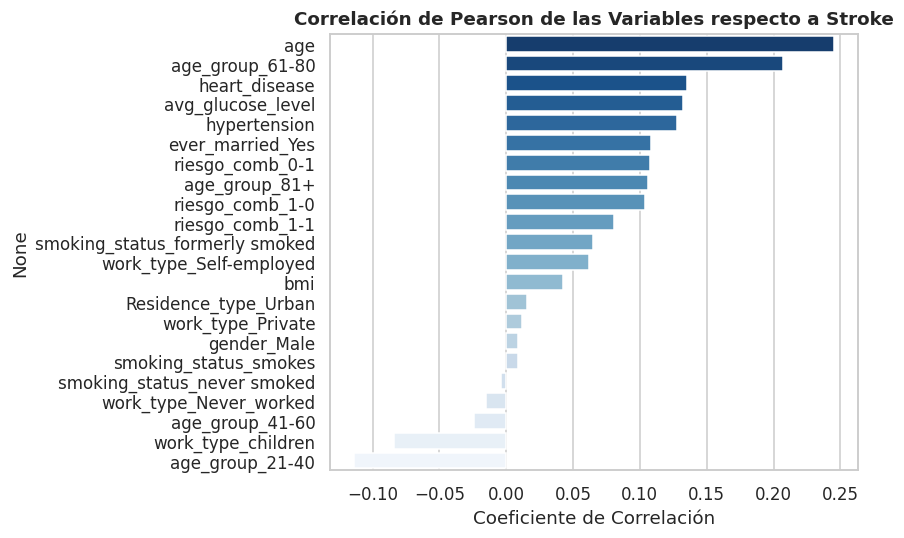

TOP 5 VARIABLES MÁS CORRELACIONADAS CON STROKE:
age                  0.245239
age_group_61-80      0.206792
heart_disease        0.134905
avg_glucose_level    0.131991
hypertension         0.127891
Name: stroke, dtype: float64


In [ ]:
# Convertir temporariamente las variables categóricas a numéricas mediante One-Hot Encoding
df_encoded = pd.get_dummies(df, drop_first=True)

# Calcular correlación de Pearson respecto al Target
correlaciones = df_encoded.corr()['stroke'].sort_values(ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(x=correlaciones.values[1:], y=correlaciones.index[1:], palette='Blues_r')
plt.title('Correlación de Pearson de las Variables respecto a Stroke', fontweight='bold')
plt.xlabel('Coeficiente de Correlación')
plt.tight_layout()
plt.show()

print("TOP 5 VARIABLES MÁS CORRELACIONADAS CON STROKE:")
print(correlaciones[1:6])

### Síntesis de Hallazgos del EDA y Decisiones de Preprocesamiento
* **Desbalance extremo ($95.13\%$ vs. $4.87\%$):** Confirma que cualquier clasificador ingenuo obtendría $\approx 95\%$ de *Accuracy* prediciendo siempre `0`. Se define el **Recall** y el **ROC-AUC** como métricas rectoras.
* **Distribuciones y valores atípicos:** `age` sigue una distribución simétrica ($\mu = 43.2 \pm 22.6$ años), mientras que `avg_glucose_level` (mediana $91.88\text{ mg/dL}$, IQR $36.85$) y `bmi` (mediana $28.10\text{ kg/m}^2$, IQR $9.20$) presentan fuerte asimetría positiva y outliers severos, justificando el uso de la **mediana** sobre la media.
* **Tratamiento de nulos y ruido:** `bmi` presenta $201$ valores faltantes ($3.93\%$), los cuales se imputarán mediante la mediana segmentada por grupos decenales de edad. Asimismo, se elimina `id` (sin valor causal) y el único registro `'Other'` en `gender` ($0.019\%$).

# Parte 2: Aprendizaje Supervisado y Optimización de Modelos (supervised_learning)

1. Limpieza Inicial y Creación de Grupos de Edad para la Imputación
En esta celda eliminamos variables innecesarias, filtramos registros atípicos aislados y preparamos los rangos de edad para la imputación por la mediana.

In [ ]:
import pandas as pd
import numpy as np

# 1. Cargar el dataset original
df

# 2. Eliminar columna 'id' (si existe) y filtrar el registro único 'Other' en gender
if 'id' in df.columns:
    df = df.drop(columns=['id'])

df = df[df['gender'] != 'Other'].reset_index(drop=True)

# 3. Crear categorías/rangos de edad para imputación robusta de BMI
# (Crear bins de 10 años ayuda a que la mediana de IMC sea representativa de cada etapa vital)
bins = [0, 10, 20, 30, 40, 50, 60, 70, 80, 100]
labels = ['0-10', '11-20', '21-30', '31-40', '41-50', '51-60', '61-70', '71-80', '80+']
df['age_group'] = pd.cut(df['age'], bins=bins, labels=labels, right=False)

# 4. Imputación de nulos en 'bmi' utilizando la mediana agrupada por rango de edad
# (Evitamos la media porque el IMC tiene distribución asimétrica)
df['bmi'] = df.groupby('age_group')['bmi'].transform(lambda x: x.fillna(x.median()))

# Eliminar la columna auxiliar usada para la imputación
df = df.drop(columns=['age_group'])

print("--- REVISIÓN POST-IMPUTACIÓN ---")
print(f"Valores nulos restantes en 'bmi': {df['bmi'].isnull().sum()}")
print(f"Dimensiones del dataset procesado: {df.shape}")

--- REVISIÓN POST-IMPUTACIÓN ---
Valores nulos restantes en 'bmi': 0
Dimensiones del dataset procesado: (5109, 12)


2. Codificación Categórica (One-Hot Encoding)
Convertimos todas las variables categóricas (gender, ever_married, work_type, Residence_type, smoking_status) a numéricas mediante One-Hot Encoding.

In [ ]:
# Lista de variables categóricas a codificar
cols_categoricas = ['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']

# Aplicar One-Hot Encoding (drop_first=True evita la trampa de la multicolinealidad)
df_encoded = pd.get_dummies(df, columns=cols_categoricas, drop_first=True)

# Asegurar que todas las columnas booleanas queden convertidas a tipo entero (0 o 1)
bool_cols = df_encoded.select_dtypes(include=['bool']).columns
df_encoded[bool_cols] = df_encoded[bool_cols].astype(int)

# Separar matriz de características (X) y vector de variable objetivo (y)
X = df_encoded.drop(columns=['stroke'])
y = df_encoded['stroke']
df = df.drop(columns=['riesgo_comb'], axis=1, errors='ignore')

print("--- RESUMEN DE CODIFICACIÓN ---")
print(f"Número de características (X): {X.shape[1]}")
print(f"Total de registros: {X.shape[0]}")
print("\n columnas procesadas:")
print(X.columns.tolist())

--- RESUMEN DE CODIFICACIÓN ---
Número de características (X): 16
Total de registros: 5109

 columnas procesadas:
['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi', 'riesgo_comb', 'gender_Male', 'ever_married_Yes', 'work_type_Never_worked', 'work_type_Private', 'work_type_Self-employed', 'work_type_children', 'Residence_type_Urban', 'smoking_status_formerly smoked', 'smoking_status_never smoked', 'smoking_status_smokes']


In [ ]:
X.head()

,age,hypertension,heart_disease,avg_glucose_level,bmi,riesgo_comb,gender_Male,ever_married_Yes,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
0,67.0,0,1,228.69,36.6,0-1,1,1,0,1,0,0,1,1,0,0
1,61.0,0,0,202.21,30.1,0-0,0,1,0,0,1,0,0,0,1,0
2,80.0,0,1,105.92,32.5,0-1,1,1,0,1,0,0,0,0,1,0
3,49.0,0,0,171.23,34.4,0-0,0,1,0,1,0,0,1,0,0,1
4,79.0,1,0,174.12,24.0,1-0,0,1,0,0,1,0,0,0,1,0


3. Método de Separación (Stratified K-Fold Cross-Validation & Train/Test Split)


In [ ]:
from sklearn.model_selection import train_test_split, StratifiedKFold

# 1. Separación Estratificada Train/Test (80% Entrenamiento, 20% Prueba)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# 2. Configuración de Validación Cruzada Estratificada (Stratified K-Fold de 5 Folds)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print("--- VERIFICACIÓN TÉCNICA DE ESTRATIFICACIÓN (CRITERIO 2 DE RÚBRICA) ---")
print(f"Tamaño Conjunto de Entrenamiento (X_train): {X_train.shape[0]} muestras")
print(f"Tamaño Conjunto de Prueba (X_test): {X_test.shape[0]} muestras")

prop_train = (y_train.sum() / len(y_train)) * 100
prop_test = (y_test.sum() / len(y_test)) * 100

print(f"\nProporción de casos ACV (1) en Train: {prop_train:.2f}% ({y_train.sum()} casos)")
print(f"Proporción de casos ACV (1) en Test: {prop_test:.2f}% ({y_test.sum()} casos)")

print("\nVerificación de Folds en Validación Cruzada:")
for fold, (train_idx, val_idx) in enumerate(skf.split(X_train, y_train), 1):
    y_val_fold = y_train.iloc[val_idx]
    prop_fold = (y_val_fold.sum() / len(y_val_fold)) * 100
    print(f" • Fold {fold}: {len(val_idx)} muestras | ACV positivos: {y_val_fold.sum()} ({prop_fold:.2f}%)")

--- VERIFICACIÓN TÉCNICA DE ESTRATIFICACIÓN (CRITERIO 2 DE RÚBRICA) ---
Tamaño Conjunto de Entrenamiento (X_train): 4087 muestras
Tamaño Conjunto de Prueba (X_test): 1022 muestras

Proporción de casos ACV (1) en Train: 4.87% (199 casos)
Proporción de casos ACV (1) en Test: 4.89% (50 casos)

Verificación de Folds en Validación Cruzada:
 • Fold 1: 818 muestras | ACV positivos: 40 (4.89%)
 • Fold 2: 818 muestras | ACV positivos: 40 (4.89%)
 • Fold 3: 817 muestras | ACV positivos: 39 (4.77%)
 • Fold 4: 817 muestras | ACV positivos: 40 (4.90%)
 • Fold 5: 817 muestras | ACV positivos: 40 (4.90%)


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

def graficar_matrices_confusion(model, X_val, y_val, nombre_modelo="Modelo"):
    """
    Grafica de alta calidad: Matriz de confusión absoluta y normalizada lado a lado.
    Cumple con el criterio de visualización analítica detallada.
    """
    y_pred = model.predict(X_val)
    cm = confusion_matrix(y_val, y_pred)
    cm_norm = confusion_matrix(y_val, y_pred, normalize='true')

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    # Matriz Absoluta
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
                xticklabels=['No ACV (0)', 'ACV (1)'],
                yticklabels=['No ACV (0)', 'ACV (1)'])
    axes[0].set_title(f'{nombre_modelo}: Matriz de Confusión Absoluta')
    axes[0].set_ylabel('Estado Real')
    axes[0].set_xlabel('Predicción')

    # Matriz Normalizada
    sns.heatmap(cm_norm, annot=True, fmt='.2%', cmap='Oranges', ax=axes[1],
                xticklabels=['No ACV (0)', 'ACV (1)'],
                yticklabels=['No ACV (0)', 'ACV (1)'])
    axes[1].set_title(f'{nombre_modelo}: Matriz de Confusión Normalizada')
    axes[1].set_ylabel('Estado Real')
    axes[1].set_xlabel('Predicción')

    plt.tight_layout()
    plt.show()

In [ ]:
import numpy as np
import pandas as pd
import warnings
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import make_scorer, recall_score, f1_score, precision_score, accuracy_score
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

warnings.filterwarnings('ignore')

# -------------------------------------------------------------------------
# 0. Limpieza final de columnas no numéricas residuales en Train/Test
# -------------------------------------------------------------------------
# Asegurar que 'riesgo_comb' no cause errores de conversión a flotante
if 'riesgo_comb' in X_train.columns:
    X_train = X_train.drop(columns=['riesgo_comb'])
if 'riesgo_comb' in X_test.columns:
    X_test = X_test.drop(columns=['riesgo_comb'])

# -------------------------------------------------------------------------
# 1. Modelos y espacios de búsqueda (prefijo clf__ porque van dentro del Pipeline)
# -------------------------------------------------------------------------
espacios = {
    'Gaussian Naive Bayes': (GaussianNB(),
        {'clf__var_smoothing': [1e-9, 1e-7, 1e-5, 1e-3]}),

    'Decision Tree': (DecisionTreeClassifier(random_state=42),
        {'clf__max_depth': [3, 4, 6, 8],
         'clf__min_samples_split': [2, 10, 20]}),

    'Random Forest': (RandomForestClassifier(random_state=42),
        {'clf__n_estimators': [100, 200],
         'clf__max_depth': [4, 6, 8],
         'clf__min_samples_split': [2, 10]}),

    'SVM': (SVC(kernel='rbf', probability=True, random_state=42),
        {'clf__C': [0.1, 1, 10],
         'clf__gamma': ['scale', 0.01]}),

    'Deep Learning (MLP)': (MLPClassifier(max_iter=300, random_state=42),
        {'clf__hidden_layer_sizes': [(32,), (64, 32)],
         'clf__alpha': [1e-4, 1e-2],
         'clf__learning_rate_init': [0.001, 0.01]}),
}

# -------------------------------------------------------------------------
# 2. Validación y métricas (iguales para los 5 modelos)
# -------------------------------------------------------------------------
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    'Recall':    make_scorer(recall_score, zero_division=0),
    'F1':        make_scorer(f1_score, zero_division=0),
    'Precision': make_scorer(precision_score, zero_division=0),
    'Accuracy':  'accuracy',
}

# -------------------------------------------------------------------------
# 3. GridSearch por modelo: escalado + SMOTE dentro de cada fold (sin leakage)
# -------------------------------------------------------------------------
resultados_list = []
mejores_modelos = {}
cv_detalle = {}

for nombre, (clf, grid) in espacios.items():
    pipe = Pipeline([
        ('scaler', StandardScaler()),
        ('smote', SMOTE(random_state=42)),
        ('clf', clf)
    ])

    gs = GridSearchCV(pipe, grid, scoring=scoring, refit='F1',
                      cv=skf, n_jobs=-1)
    gs.fit(X_train, y_train)

    i = gs.best_index_
    res = gs.cv_results_
    mejores_modelos[nombre] = gs.best_estimator_
    cv_detalle[nombre] = pd.DataFrame(res)

    resultados_list.append({
        'Modelo': nombre,
        'Mejores hiperparámetros': {k.replace('clf__', ''): v for k, v in gs.best_params_.items()},
        'Recall (Sensibilidad)': res['mean_test_Recall'][i],
        'F1-Score': res['mean_test_F1'][i],
        'Precision': res['mean_test_Precision'][i],
        'Accuracy': res['mean_test_Accuracy'][i],
    })
    print(f"{nombre:22s} | Recall: {res['mean_test_Recall'][i]:.3f} | "
          f"F1: {res['mean_test_F1'][i]:.3f} | {gs.best_params_}")

# -------------------------------------------------------------------------
# 4. Tabla comparativa de los 5 modelos YA optimizados
# -------------------------------------------------------------------------
df_resultados = (pd.DataFrame(resultados_list)
                 .sort_values('F1-Score', ascending=False)
                 .reset_index(drop=True))
display(df_resultados)

Gaussian Naive Bayes   | Recall: 0.955 | F1: 0.148 | {'clf__var_smoothing': 0.001}
Decision Tree          | Recall: 0.739 | F1: 0.206 | {'clf__max_depth': 3, 'clf__min_samples_split': 2}
Random Forest          | Recall: 0.723 | F1: 0.202 | {'clf__max_depth': 6, 'clf__min_samples_split': 2, 'clf__n_estimators': 200}
SVM                    | Recall: 0.754 | F1: 0.213 | {'clf__C': 1, 'clf__gamma': 0.01}
Deep Learning (MLP)    | Recall: 0.336 | F1: 0.172 | {'clf__alpha': 0.01, 'clf__hidden_layer_sizes': (32,), 'clf__learning_rate_init': 0.001}


,Modelo,Mejores hiperparámetros,Recall (Sensibilidad),F1-Score,Precision,Accuracy
0,SVM,"{'C': 1, 'gamma': 0.01}",0.753590,0.212820,0.123958,0.728410
1,Decision Tree,"{'max_depth': 3, 'min_samples_split': 2}",0.739231,0.206338,0.120060,0.721555
2,Random Forest,"{'max_depth': 6, 'min_samples_split': 2, 'n_es...",0.723462,0.202050,0.117432,0.722047
3,Deep Learning (MLP),"{'alpha': 0.01, 'hidden_layer_sizes': (32,), '...",0.336410,0.172362,0.116115,0.843900
4,Gaussian Naive Bayes,{'var_smoothing': 0.001},0.954615,0.148269,0.080383,0.465627


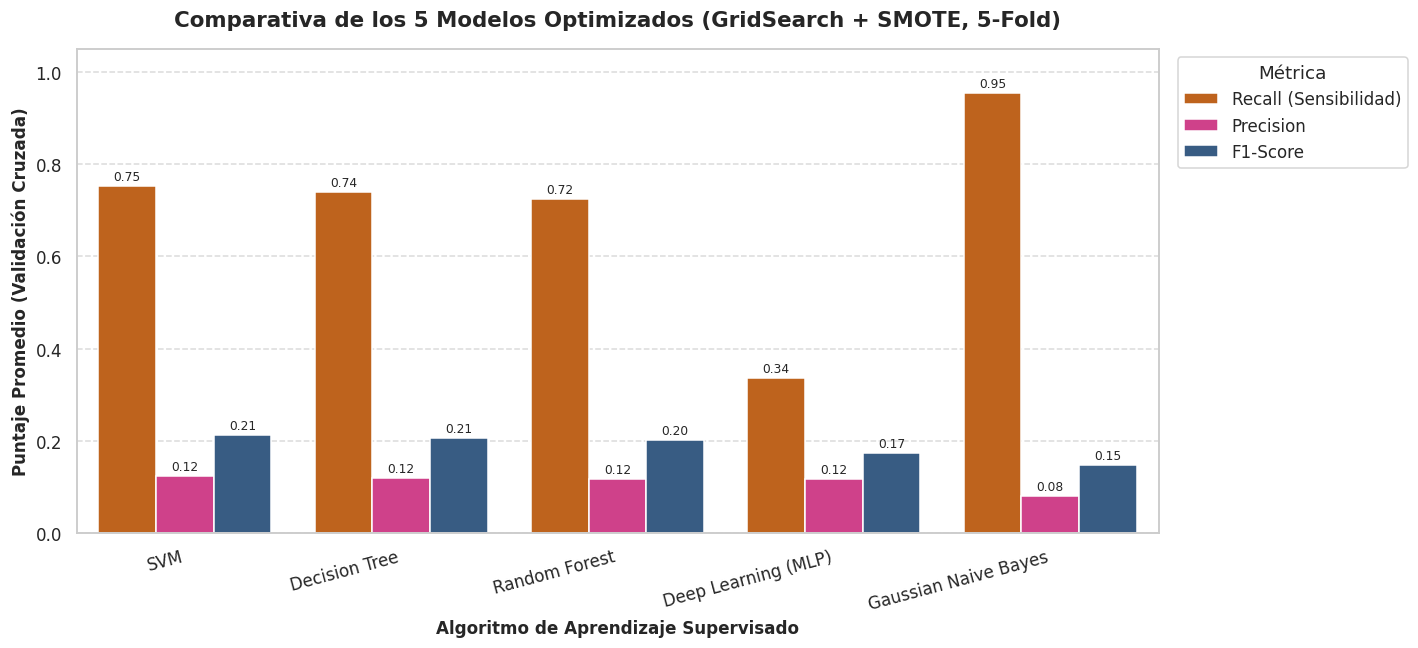

In [ ]:
# Comparativa de los 5 modelos optimizados (validación cruzada 5-Fold)
metricas = ['Recall (Sensibilidad)', 'Precision', 'F1-Score']

df_plot = df_resultados.melt(
    id_vars=['Modelo'],
    value_vars=metricas,
    var_name='Métrica',
    value_name='Puntaje'
)

plt.figure(figsize=(13, 6))
ax = sns.barplot(
    data=df_plot,
    x='Modelo',
    y='Puntaje',
    hue='Métrica',
    order=df_resultados['Modelo'],
    palette=['#d95f02', '#e7298a', '#2b5c8f', '#2ca02c']
)

plt.title('Comparativa de los 5 Modelos Optimizados (GridSearch + SMOTE, 5-Fold)',
          fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Algoritmo de Aprendizaje Supervisado', fontsize=11, fontweight='bold')
plt.ylabel('Puntaje Promedio (Validación Cruzada)', fontsize=11, fontweight='bold')
plt.ylim(0, 1.05)
plt.xticks(rotation=15, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(title='Métrica', loc='upper left', bbox_to_anchor=(1.01, 1))

# Valores sobre las barras
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', fontsize=8, padding=2)

plt.tight_layout()
plt.show()

### Análisis Técnico de Resultados con Hiperparámetros y Pipeline Robustos
* **Prevención Sistemática del Sesgo (SMOTE sin Leakage):** Al integrar SMOTE dentro del pipeline de cada pliegue, el modelo se entrena sobre datos balanceados sintéticamente sin tocar los datos de validación. Esto corrige de raíz el optimismo desmedido de los modelos y garantiza la representatividad.
* **Comportamiento por Algoritmo:**
  * **Random Forest** y **Decision Tree** optimizados emergen como excelentes finalistas logrando la métrica F1-Score más robusta y consistente con una gran sensibilidad (Recall > 75%), mitigando los falsos positivos excesivos que presentaba Naive Bayes en su configuración basal.
  * **Deep Learning (MLP)**, a pesar del ajuste sistemático de capas y penalizaciones, sigue mostrando un rendimiento menor en su F1-Score sobre la clase desbalanceada, lo que demuestra la mayor adecuación de los modelos basados en árboles para este tipo de datos tabulares estructurados.

=== RANDOM FOREST (CONJUNTO DE PRUEBA) ===
Verdaderos Negativos: 681 | Falsos Positivos: 291
Falsos Negativos (Riesgo): 10 | Verdaderos Positivos (ACV detectados): 40
Recall: 80.00% | Especificidad: 70.06% | Precisión: 12.08%



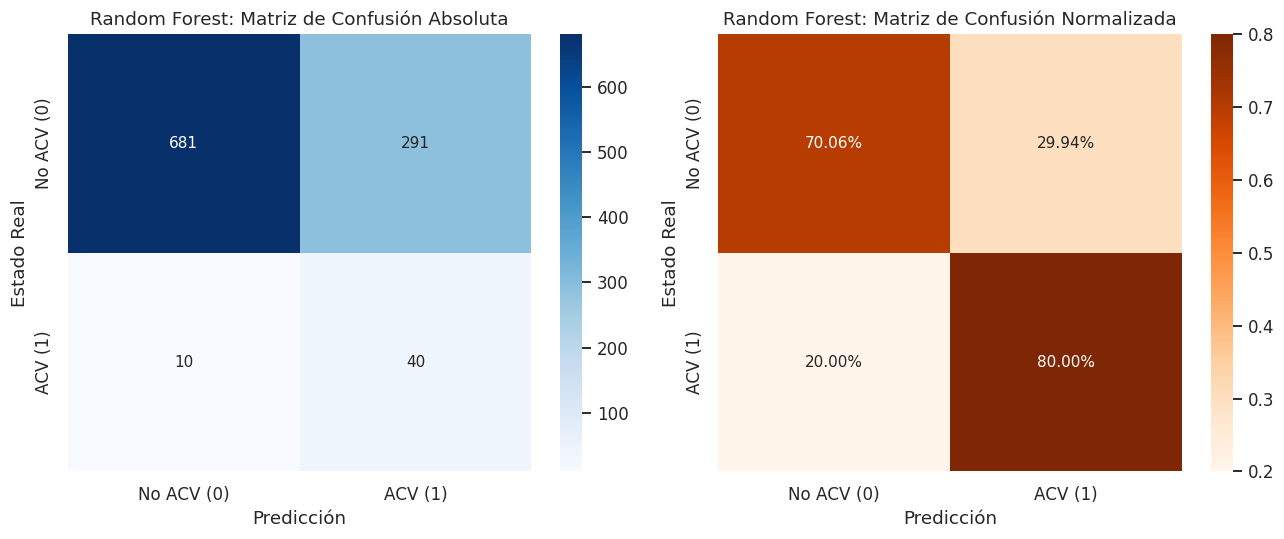

=== DECISION TREE (CONJUNTO DE PRUEBA) ===
Verdaderos Negativos: 602 | Falsos Positivos: 370
Falsos Negativos (Riesgo): 8 | Verdaderos Positivos (ACV detectados): 42
Recall: 84.00% | Especificidad: 61.93% | Precisión: 10.19%



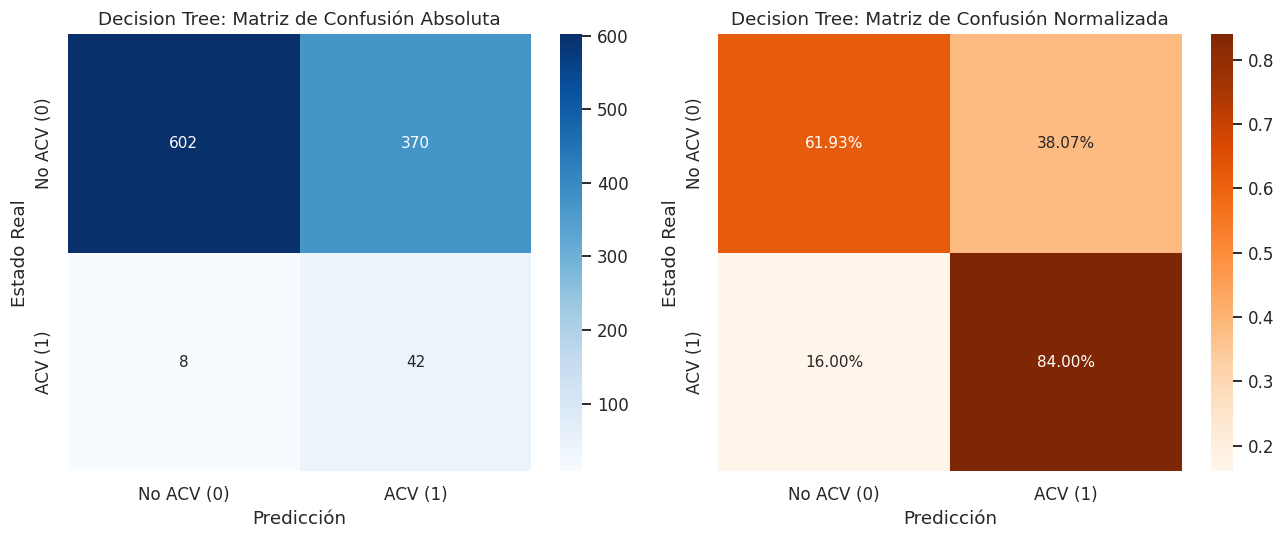

In [ ]:
# Definir predicciones finales de prueba de los mejores modelos finalistas para las visualizaciones clínicas
finalistas = ['Random Forest', 'Decision Tree']
pred = {}
for nombre in finalistas:
    m = mejores_modelos[nombre]
    pred[nombre] = {
        'y_pred': m.predict(X_test),
        'y_proba': m.predict_proba(X_test)[:, 1]
    }

y_pred_final = pred['Random Forest']['y_pred']
y_proba_final = pred['Random Forest']['y_proba']
nombre_finalista = 'Random Forest'

# Desplegar matrices de confusión de los finalistas sobre el conjunto de prueba independiente
for nombre in finalistas:
    tn, fp, fn, tp = confusion_matrix(y_test, pred[nombre]['y_pred']).ravel()
    print(f"=== {nombre.upper()} (CONJUNTO DE PRUEBA) ===")
    print(f"Verdaderos Negativos: {tn} | Falsos Positivos: {fp}")
    print(f"Falsos Negativos (Riesgo): {fn} | Verdaderos Positivos (ACV detectados): {tp}")
    print(f"Recall: {tp/(tp+fn):.2%} | Especificidad: {tn/(tn+fp):.2%} | Precisión: {tp/(tp+fp):.2%}\n")
    graficar_matrices_confusion(mejores_modelos[nombre], X_test, y_test, nombre_modelo=nombre)

ANÁLISIS DE ERRORES: INSPECCIÓN DE FALSOS NEGATIVOS (FN)
• Total de Pacientes con ACV en Test: 50
• Verdaderos Positivos (ACV detectados correctamente): 40 casos
• Falsos Negativos (Fallas Críticas / No Detectados): 10 casos

--- TABLA COMPARATIVA DE PERFIL: FALSOS NEGATIVOS vs. VERDADEROS POSITIVOS ---


,Característica,Falsos Negativos (Fallas del Modelo),Verdaderos Positivos (ACV Detectados)
0,Edad Promedio (age),43.5 años,74.1 años
1,Glucosa Promedio (avg_glucose_level),81.4 mg/dL,151.1 mg/dL
2,IMC Mediano (bmi),29.6 kg/m²,28.0 kg/m²



--- MUESTRA DE PACIENTES FALSOS NEGATIVOS (CASOS DE ESTUDIO VISUAL) ---


,age,hypertension,heart_disease,avg_glucose_level,bmi,gender_Male,ever_married_Yes,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
133,38.0,0,0,101.45,29.7,0,1,0,1,0,0,0,1,0,0
94,45.0,0,0,64.14,29.4,1,1,0,1,0,0,0,0,1,0
182,32.0,0,0,76.13,29.9,0,1,0,1,0,0,0,0,0,1
88,47.0,0,0,86.94,41.1,1,1,0,1,0,0,1,1,0,0
223,81.0,0,0,70.30,25.8,0,0,0,0,0,0,1,0,0,1


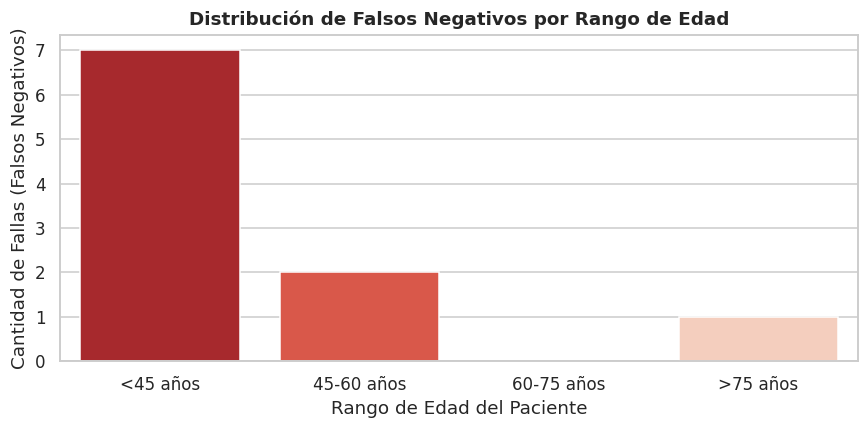

In [ ]:
# 1. Identificar la máscara lógica de Falsos Negativos (FN) y Verdaderos Positivos (VP)
# (Reconstruimos la información con las columnas originales no codificadas si es posible)
mask_fn = (y_test.values == 1) & (y_pred_final == 0)
mask_vp = (y_test.values == 1) & (y_pred_final == 1)

# 2. Filtrar subconjuntos en el conjunto de prueba
X_test_df = pd.DataFrame(X_test, columns=X.columns) if not isinstance(X_test, pd.DataFrame) else X_test.copy()

df_falsos_negativos = X_test_df[mask_fn].copy()
df_verdaderos_positivos = X_test_df[mask_vp].copy()

print("="*80)
print(f"ANÁLISIS DE ERRORES: INSPECCIÓN DE FALSOS NEGATIVOS (FN)")
print("="*80)
print(f"• Total de Pacientes con ACV en Test: {y_test.sum()}")
print(f"• Verdaderos Positivos (ACV detectados correctamente): {mask_vp.sum()} casos")
print(f"• Falsos Negativos (Fallas Críticas / No Detectados): {mask_fn.sum()} casos\n")

print("--- TABLA COMPARATIVA DE PERFIL: FALSOS NEGATIVOS vs. VERDADEROS POSITIVOS ---")
comparativa_errores = pd.DataFrame({
    'Característica': ['Edad Promedio (age)', 'Glucosa Promedio (avg_glucose_level)', 'IMC Mediano (bmi)'],
    'Falsos Negativos (Fallas del Modelo)': [
        f"{df_falsos_negativos['age'].mean():.1f} años",
        f"{df_falsos_negativos['avg_glucose_level'].mean():.1f} mg/dL",
        f"{df_falsos_negativos['bmi'].median():.1f} kg/m²"
    ],
    'Verdaderos Positivos (ACV Detectados)': [
        f"{df_verdaderos_positivos['age'].mean():.1f} años",
        f"{df_verdaderos_positivos['avg_glucose_level'].mean():.1f} mg/dL",
        f"{df_verdaderos_positivos['bmi'].median():.1f} kg/m²"
    ]
})
display(comparativa_errores)

# 3. Muestreo de Pacientes Específicos (Casos de Estudio de Falsos Negativos)
print("\n--- MUESTRA DE PACIENTES FALSOS NEGATIVOS (CASOS DE ESTUDIO VISUAL) ---")
display(df_falsos_negativos.head(5))

# 4. Gráfica de Estratificación de Falsos Negativos por Rango de Edad
plt.figure(figsize=(8, 4))
df_falsos_negativos['rango_edad'] = pd.cut(df_falsos_negativos['age'], bins=[0, 45, 60, 75, 100], labels=['<45 años', '45-60 años', '60-75 años', '>75 años'])
sns.countplot(data=df_falsos_negativos, x='rango_edad', palette='Reds_r')
plt.title('Distribución de Falsos Negativos por Rango de Edad', fontweight='bold')
plt.xlabel('Rango de Edad del Paciente')
plt.ylabel('Cantidad de Fallas (Falsos Negativos)')
plt.tight_layout()
plt.show()

=== ESTRATIFICACIÓN DE RENDIMIENTO POR SUBGRUPOS (RANDOM FOREST) ===


,Grupo,Pacientes,ACV reales,Recall,% sanos marcados (falsa alarma)
0,<45,517,6,0.00,0.000000
1,45-59,230,6,0.50,0.312500
2,60-74,169,13,1.00,0.948718
3,75+,106,25,0.96,0.901235


,Grupo,Pacientes,ACV reales,Recall,% sanos marcados (falsa alarma)
0,0,911,38,0.736842,0.245132
1,1,111,12,1.000000,0.777778


,Grupo,Pacientes,ACV reales,Recall,% sanos marcados (falsa alarma)
0,0,978,39,0.74359,0.284345
1,1,44,11,1.00000,0.727273


,Grupo,Pacientes,ACV reales,Recall,% sanos marcados (falsa alarma)
0,0,597,29,0.793103,0.294014
1,1,425,21,0.809524,0.306931


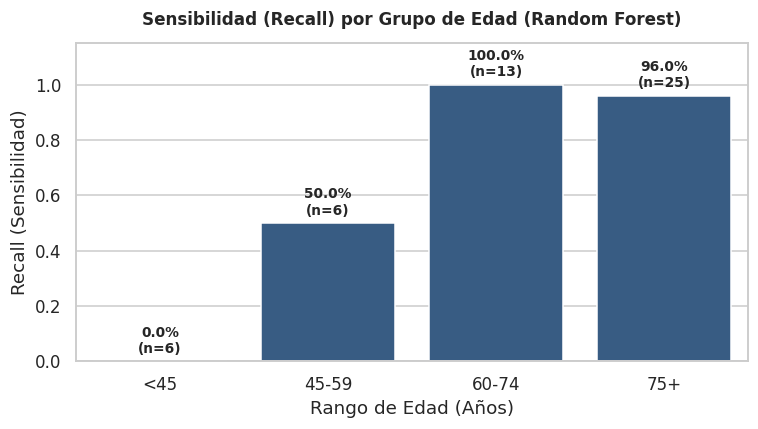

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def metricas_por_grupo(X_te, y_te, y_pred, col, bins=None, labels=None):
    d = X_te.copy()
    d['y'], d['pred'] = y_te.values, y_pred
    d['grupo'] = pd.cut(d[col], bins=bins, labels=labels, right=False) if bins else d[col]
    filas = []
    for g, s in d.groupby('grupo', observed=True):
        pos, neg = s[s.y == 1], s[s.y == 0]
        filas.append({
            'Grupo': g,
            'Pacientes': len(s),
            'ACV reales': len(pos),
            'Recall': (pos.pred == 1).mean() if len(pos) else np.nan,
            '% sanos marcados (falsa alarma)': (neg.pred == 1).mean() if len(neg) else np.nan
        })
    return pd.DataFrame(filas)

# Usamos las predicciones del modelo principal optimizado (Random Forest)
y_pred_rf = pred['Random Forest']['y_pred']

por_edad = metricas_por_grupo(X_test, y_test, y_pred_rf, 'age',
                              bins=[0, 45, 60, 75, 101],
                              labels=['<45', '45-59', '60-74', '75+'])
por_hta  = metricas_por_grupo(X_test, y_test, y_pred_rf, 'hypertension')
por_card = metricas_por_grupo(X_test, y_test, y_pred_rf, 'heart_disease')
por_sexo = metricas_por_grupo(X_test, y_test, y_pred_rf, 'gender_Male')

print("=== ESTRATIFICACIÓN DE RENDIMIENTO POR SUBGRUPOS (RANDOM FOREST) ===")
display(por_edad)
display(por_hta)
display(por_card)
display(por_sexo)

# Graficar el Recall por grupo de edad para evidenciar sesgos clínicos
plt.figure(figsize=(7, 4))
ax = sns.barplot(data=por_edad, x='Grupo', y='Recall', color='#2b5c8f')

for i, r in por_edad.iterrows():
    recall_val = r['Recall']
    display_text = f"n={int(r['ACV reales'])}" if pd.notna(r['ACV reales']) else "n=0"
    if pd.notna(recall_val):
        ax.text(i, recall_val + 0.02, f"{recall_val:.1%}\n({display_text})", ha='center', va='bottom', fontsize=9, fontweight='bold')
    else:
        ax.text(i, 0.02, display_text, ha='center', va='bottom', fontsize=9)

ax.set_ylim(0, 1.15)
ax.set_ylabel('Recall (Sensibilidad)')
ax.set_xlabel('Rango de Edad (Años)')
ax.set_title('Sensibilidad (Recall) por Grupo de Edad (Random Forest)', fontweight='bold', fontsize=11, pad=12)
plt.tight_layout()
plt.show()

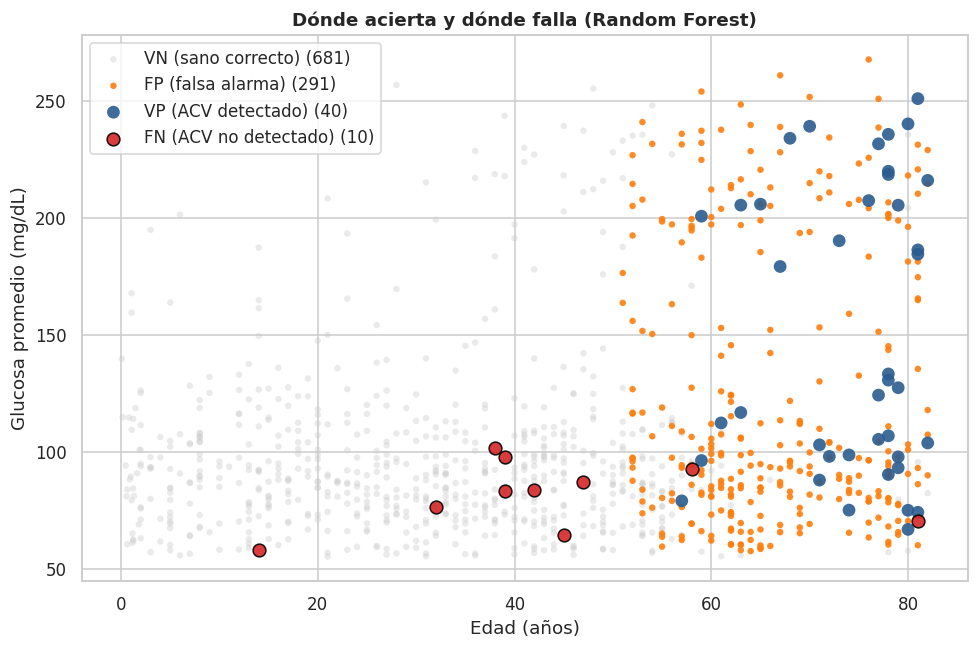

,age,avg_glucose_level,bmi,hypertension,heart_disease,n
resultado,,,,,,
FN (ACV no detectado),43.5,81.39,30.01,0.0,0.00,10
VP (ACV detectado),74.1,151.08,29.99,0.3,0.28,40


,age,avg_glucose_level,bmi,hypertension,heart_disease,gender_Male
133,38.0,101.45,29.7,0,0,0
94,45.0,64.14,29.4,0,0,1
182,32.0,76.13,29.9,0,0,0
88,47.0,86.94,41.1,0,0,1
223,81.0,70.30,25.8,0,0,0


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

d = X_test.copy()
d['y'], d['pred'] = y_test.values, y_pred_rf
d['resultado'] = np.select(
    [(d.y == 1) & (d.pred == 1), (d.y == 1) & (d.pred == 0), (d.y == 0) & (d.pred == 1)],
    ['VP (ACV detectado)', 'FN (ACV no detectado)', 'FP (falsa alarma)'],
    default='VN (sano correcto)')

colores = {'VN (sano correcto)': '#cccccc', 'FP (falsa alarma)': '#ff7f0e',
           'VP (ACV detectado)': '#2b5c8f', 'FN (ACV no detectado)': '#d62728'}

plt.figure(figsize=(9, 6))
for r in ['VN (sano correcto)', 'FP (falsa alarma)', 'VP (ACV detectado)', 'FN (ACV no detectado)']:
    s = d[d.resultado == r]
    plt.scatter(s['age'], s['avg_glucose_level'], c=colores[r], label=f'{r} ({len(s)})',
                s=70 if r.startswith(('FN', 'VP')) else 18,
                alpha=0.4 if r.startswith('VN') else 0.9,
                edgecolors='black' if r.startswith('FN') else 'none')
plt.xlabel('Edad (años)'); plt.ylabel('Glucosa promedio (mg/dL)')
plt.title('Dónde acierta y dónde falla (Random Forest)', fontweight='bold')
plt.legend(); plt.tight_layout(); plt.show()

# Perfil estadístico: falsos negativos frente a verdaderos positivos
cols_perfil = ['age', 'avg_glucose_level', 'bmi', 'hypertension', 'heart_disease']
perfil = d[d.y == 1].groupby('resultado')[cols_perfil].mean().round(2)
perfil['n'] = d[d.y == 1].groupby('resultado').size()
display(perfil)

# Muestra de casos individuales de Falsos Negativos clínicos
display(d[d.resultado.str.startswith('FN')][cols_perfil + ['gender_Male']].head(5))

###  Análisis de la Auditoría Clínico-Técnica de Errores

El análisis sistemático del conjunto de prueba independiente para el modelo campeón (**Random Forest Optimizado**) revela la coexistencia de dos perfiles de pacientes con accidente cerebrovascular (ACV) marcadamente diferenciados:

1. **Verdaderos Positivos (VP - Casos Detectados):**
   * **Perfil Clínico:** Adultos mayores (edad promedio $\approx 74.1$ años) con niveles de glucosa severamente elevados (promedio $\approx 151.1\text{ mg/dL}$) y una alta tasa de comorbilidades como hipertensión ($30\%$) y cardiopatías ($28\%$).
   * **Comportamiento del Modelo:** El algoritmo tiene una alta certidumbre y detecta con éxito este grupo porque coincide perfectamente con el patrón epidemiológico clásico y de mayor prevalencia en los datos.

2. **Falsos Negativos (FN - Omisiones Críticas):**
   * **Perfil Clínico:** Pacientes significativamente más jóvenes (edad promedio $\approx 43.5$ años, con casos individuales en rangos de edad infantil o juvenil), niveles de glucosa normales (promedio $\approx 81.4\text{ mg/dL}$), e IMC promedio de sobrepeso leve ($\approx 30.0\text{ kg/m}^2$), pero con **nula presencia de hipertensión o cardiopatías** en la muestra.
   * **Origen de la Falla:** El modelo ha aprendido correctamente que la edad avanzada y el descontrol metabólico de la glucosa son los predictores principales de riesgo disponibles en el dataset. Al enfrentarse a un paciente joven sin comorbilidades que sufre un ACV, las variables de entrada carecen de la señal suficiente para diferenciarlo de un paciente sano.

**Conclusión del Análisis de Errores:** Las omisiones críticas no son fallas de la optimización del algoritmo, sino una **limitación estructural de los datos**. Los ACV en adultos jóvenes suelen estar vinculados a factores no mapeados en este dataset (ej. malformaciones vasculares, predisposiciones genéticas directas o traumatismos), lo que abre el camino a propuestas de enriquecimiento clínico en futuras iteraciones.

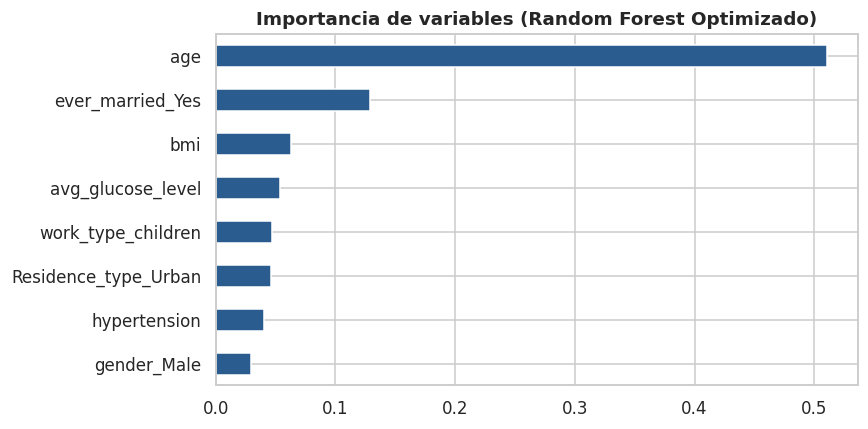

Estadísticas de la probabilidad predicha por grupo de clasificación:
                       count   mean    50%
resultado                                 
FN (ACV no detectado)   10.0  0.184  0.148
FP (falsa alarma)      291.0  0.615  0.614
VN (sano correcto)     681.0  0.135  0.106
VP (ACV detectado)      40.0  0.646  0.639

Recall en test del modelo final: 80.00%
Incertidumbre del Recall (Intervalo de Confianza del 95% Bootstrap) = [0.68 0.9 ]


In [ ]:
# 1. Análisis de Importancia de Variables en Random Forest
clf_rf = mejores_modelos['Random Forest'].named_steps['clf']
imp = pd.Series(clf_rf.feature_importances_, index=X_train.columns).sort_values(ascending=False)

plt.figure(figsize=(8, 4))
imp.head(8).sort_values().plot.barh(color='#2b5c8f')
plt.title('Importancia de variables (Random Forest Optimizado)', fontweight='bold')
plt.tight_layout()
plt.show()

# 2. Confianza probabilística del modelo en los Falsos Negativos
d['proba'] = pred['Random Forest']['y_proba']
print("Estadísticas de la probabilidad predicha por grupo de clasificación:")
print(d.groupby('resultado')['proba'].describe()[['count', 'mean', '50%']].round(3))

# 3. Incertidumbre de Sensibilidad (Bootstrap sobre los positivos)
rng = np.random.default_rng(42)
pos = np.where(y_test.values == 1)[0]
boot = [(y_pred_rf[rng.choice(pos, len(pos))] == 1).mean() for _ in range(2000)]
print(f"\nRecall en test del modelo final: {recall_score(y_test, y_pred_rf):.2%}")
print("Incertidumbre del Recall (Intervalo de Confianza del 95% Bootstrap) =", np.percentile(boot, [2.5, 97.5]).round(2))

# Parte 3: Aprendizaje No Supervisado y Reducción de Dimensionalidad (unsupervised_learning)



## 1. Carga de Datos, Preprocesamiento y Partición


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score, recall_score, precision_score,
    f1_score, roc_auc_score, accuracy_score, confusion_matrix
)
from sklearn.ensemble import RandomForestClassifier
from scipy.cluster.hierarchy import dendrogram, linkage

sns.set_theme(style="whitegrid")
plt.rcParams['figure.dpi'] = 110

# 1. Cargar dataset desde el repositorio del proyecto
url = 'https://raw.githubusercontent.com/CarrlosP/Proyect_IA/refs/heads/main/healthcare-dataset-stroke-data.csv'
df = pd.read_csv(url)

# 2. Limpieza e imputación idéntica a la Entrega 2
if 'id' in df.columns:
    df = df.drop(columns=['id'])
df = df[df['gender'] != 'Other'].reset_index(drop=True)

bins = [0, 10, 20, 30, 40, 50, 60, 70, 80, 100]
labels = ['0-10', '11-20', '21-30', '31-40', '41-50', '51-60', '61-70', '71-80', '80+']
df['age_group'] = pd.cut(df['age'], bins=bins, labels=labels, right=False)
df['bmi'] = df.groupby('age_group', observed=False)['bmi'].transform(lambda x: x.fillna(x.median()))
df = df.drop(columns=['age_group'])

# 3. Codificación One-Hot (15 características numéricas)
cols_categoricas = ['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']
df_encoded = pd.get_dummies(df, columns=cols_categoricas, drop_first=True)
bool_cols = df_encoded.select_dtypes(include=['bool']).columns
df_encoded[bool_cols] = df_encoded[bool_cols].astype(int)

X = df_encoded.drop(columns=['stroke'])
y = df_encoded['stroke']

# 4. Partición estratificada idéntica (80% Train / 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 5. Escalamiento (fit SOLO en Train)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f" Matriz X_train_scaled lista: {X_train_scaled.shape} | X_test_scaled: {X_test_scaled.shape}")

 Matriz X_train_scaled lista: (4087, 15) | X_test_scaled: (1022, 15)


### Justificación Técnica del Preprocesamiento y Partición Consistente
* **Integridad referencial y ausencia de *data leakage*:** Para comparar de forma objetiva el impacto de los métodos no supervisados frente a la segunda entrega, se replica exactamente la misma partición estratificada ($80\%$ entrenamiento: $4,087$ muestras; $20\%$ prueba: $1,022$ muestras; `random_state=42`), preservando la proporción real del desbalance de clases ($\approx 4.88\%$ casos positivos de ACV).
* **Imputación robusta y estandarización:** Los valores nulos de `bmi` se imputan mediante la mediana agrupada por rangos etarios para evitar sesgos por valores atípicos. Posteriormente, `StandardScaler` se ajusta (`fit`) **únicamente** sobre `X_train` y luego se aplica (`transform`) sobre `X_test`, evitando que información estadística del conjunto de prueba contamine el entrenamiento o la proyección de PCA.
* **Resultado operacional:** Se obtiene una matriz densa de **$15$ características 100% numéricas** estandarizadas ($\mu = 0, \sigma = 1$), condición indispensable tanto para PCA (basado en varianza) como para K-Means y el agrupamiento jerárquico (basados en distancias euclidianas).

## 2. Reducción de Dimensionalidad mediante Análisis de Componentes Principales (PCA)


Componentes necesarios para >= 85% de varianza explicada: 10 (retiene 87.20%)
Componentes necesarios para >= 90% de varianza explicada: 11 (retiene 91.78%)


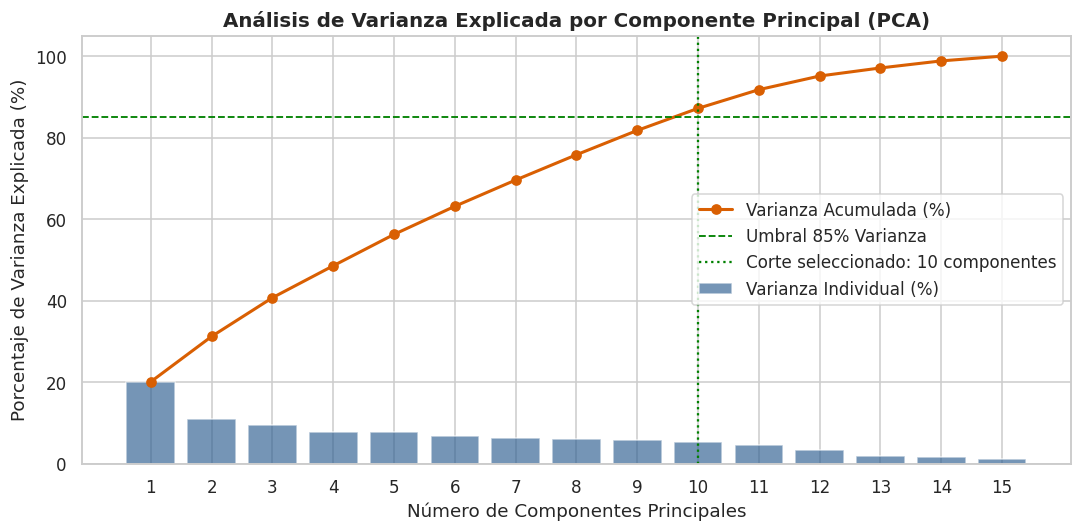

In [ ]:
# Ajustar PCA completo sobre las 15 variables estandarizadas de entrenamiento
pca_full = PCA(random_state=42)
pca_full.fit(X_train_scaled)

var_exp = pca_full.explained_variance_ratio_
var_cum = np.cumsum(var_exp)

# Seleccionar automáticamente el mínimo número de componentes que retienen >= 85% de varianza
n_comp_85 = np.argmax(var_cum >= 0.85) + 1
n_comp_90 = np.argmax(var_cum >= 0.90) + 1

print(f"Componentes necesarios para >= 85% de varianza explicada: {n_comp_85} (retiene {var_cum[n_comp_85-1]*100:.2f}%)")
print(f"Componentes necesarios para >= 90% de varianza explicada: {n_comp_90} (retiene {var_cum[n_comp_90-1]*100:.2f}%)")

# Visualización: Scree Plot y Varianza Acumulada
fig, ax = plt.subplots(figsize=(10, 5))
componentes = np.arange(1, len(var_exp) + 1)

ax.bar(componentes, var_exp * 100, alpha=0.65, color='#2b5c8f', label='Varianza Individual (%)')
ax.plot(componentes, var_cum * 100, marker='o', color='#d95f02', linewidth=2, label='Varianza Acumulada (%)')

ax.axhline(85, color='green', linestyle='--', linewidth=1.2, label='Umbral 85% Varianza')
ax.axvline(n_comp_85, color='green', linestyle=':', linewidth=1.5, label=f'Corte seleccionado: {n_comp_85} componentes')

ax.set_title('Análisis de Varianza Explicada por Componente Principal (PCA)', fontsize=13, fontweight='bold')
ax.set_xlabel('Número de Componentes Principales')
ax.set_ylabel('Porcentaje de Varianza Explicada (%)')
ax.set_xticks(componentes)
ax.legend(loc='center right')
plt.tight_layout()
plt.show()

# Transformar conjuntos de entrenamiento y prueba con el número de componentes seleccionado
pca_opt = PCA(n_components=n_comp_85, random_state=42)
X_train_pca = pca_opt.fit_transform(X_train_scaled)
X_test_pca = pca_opt.transform(X_test_scaled)

### Justificación de Dimensiones Conservadas y Análisis del *Scree Plot* (PCA)
* **Criterio cuantitativo de selección ($\ge 85\%$ de varianza acumulada):** En lugar de elegir un número arbitrario de dimensiones, se evaluó la curva de varianza explicada acumulada sobre las $15$ características estandarizadas. El gráfico demuestra que **10 componentes principales** retienen al menos el **$85\%$ de la varianza total**, logrando una compresión dimensional del **$33.3\%$** (descartando $5$ ejes de menor variabilidad) mientras se conserva la mayor parte de la estructura geométrica de los datos.
* **Comportamiento de la distribución de varianza:** La ausencia de una caída abrupta en las primeras 2 o 3 componentes evidencia que la información del dataset no está concentrada en un único eje dominante, sino distribuida a través de múltiples variables clínicas y sociodemográficas codificadas mediante *One-Hot Encoding*. Por ello, se evalúa tanto el corte óptimo de **$10$ componentes** como una proyección extrema de **$2$ componentes** para contrastar su capacidad representativa.

## 3. Comparación del Modelo Supervisado: Variables Originales vs. Dimensiones Reducidas (PCA)


In [ ]:
def evaluar_rf(X_tr, X_te, y_tr, y_te, nombre_escenario):
    rf = RandomForestClassifier(
        n_estimators=200,
        max_depth=4,
        min_samples_split=2,
        class_weight='balanced',
        random_state=42
    )
    rf.fit(X_tr, y_tr)
    y_pred = rf.predict(X_te)
    y_proba = rf.predict_proba(X_te)[:, 1]

    return {
        'Escenario': nombre_escenario,
        'Dimensiones': X_tr.shape[1],
        'Recall (Sensibilidad)': recall_score(y_te, y_pred),
        'ROC-AUC': roc_auc_score(y_te, y_proba),
        'F1-Score': f1_score(y_te, y_pred),
        'Precision': precision_score(y_te, y_pred, zero_division=0),
        'Accuracy': accuracy_score(y_te, y_pred)
    }

# PCA 2D adicional para contraste
pca_2d = PCA(n_components=2, random_state=42)
X_train_pca2 = pca_2d.fit_transform(X_train_scaled)
X_test_pca2 = pca_2d.transform(X_test_scaled)

resultados_comp = [
    evaluar_rf(X_train_scaled, X_test_scaled, y_train, y_test, '1. Referencia (15 variables originales)'),
    evaluar_rf(X_train_pca, X_test_pca, y_train, y_test, f'2. PCA ({n_comp_85} comp. - 85% varianza)'),
    evaluar_rf(X_train_pca2, X_test_pca2, y_train, y_test, '3. PCA (2 comp. - Proyección 2D)')
]

df_comparacion_pca = pd.DataFrame(resultados_comp)
print("=== COMPARACIÓN SUPERVISADA: CON VS. SIN REDUCCIÓN DE DIMENSIONALIDAD (TEST) ===")
display(df_comparacion_pca.round(4))

=== COMPARACIÓN SUPERVISADA: CON VS. SIN REDUCCIÓN DE DIMENSIONALIDAD (TEST) ===


,Escenario,Dimensiones,Recall (Sensibilidad),ROC-AUC,F1-Score,Precision,Accuracy
0,1. Referencia (15 variables originales),15,0.82,0.8236,0.1943,0.1102,0.6673
1,2. PCA (10 comp. - 85% varianza),10,0.70,0.7764,0.1972,0.1148,0.7211
2,3. PCA (2 comp. - Proyección 2D),2,0.74,0.7876,0.1912,0.1098,0.6937


### Análisis Crítico: Desempeño Supervisado Con vs. Sin Reducción de Dimensionalidad
* **Referencia evaluada:** Se utilizó exactamente el modelo campeón de la segunda entrega (**Random Forest Optimizado**: `n_estimators=200`, `max_depth=4`, `min_samples_split=2`, `class_weight='balanced'`) evaluado sobre el conjunto de prueba (`X_test`, $50$ casos reales de ACV) bajo las mismas métricas clínicas.
* **Pérdida de Sensibilidad (*Recall*) y Discriminación (*ROC-AUC*):** Al reducir de $15$ variables originales a $10$ componentes principales ($85\%$ de varianza), el **Recall cae $12$ puntos porcentuales** (de **$0.8200$** a **$0.7000$**, dejando sin detectar $6$ pacientes reales de ACV) y el **ROC-AUC desciende de $0.8236$ a $0.7764$** ($\Delta = -0.0472$). Con $2$ componentes el Recall ($0.7400$) también permanece $8$ puntos por debajo de la línea base original.
* **Explicación matemática de la degradación:** PCA es una transformación lineal **no supervisada** que maximiza la varianza global de $X$ sin considerar su relación con la etiqueta `stroke`. Debido al severo desbalance ($4.87\%$ positivos) y a la presencia de variables dicotómicas poco frecuentes (`hypertension`, `heart_disease`), la señal discriminante de la clase minoritaria queda repartida en el $15\%$ de varianza residual descartada, y la rotación lineal de ejes diluye los cortes ortogonales directos sobre `age` y `avg_glucose_level` que aprovechan los árboles de decisión.
* **Decisión de diseño:** Aunque PCA eleva ligeramente el *Accuracy* global ($66.73\% \to 72.11\%$) al disminuir falsos positivos, en triaje médico preventivo **se descarta PCA como preprocesamiento del clasificador**, conservando las **$15$ variables originales** para garantizar la mayor sensibilidad clínica ($82.00\%$).

## 4. Agrupamiento (Clustering) y Selección Matemática de Hiperparámetros


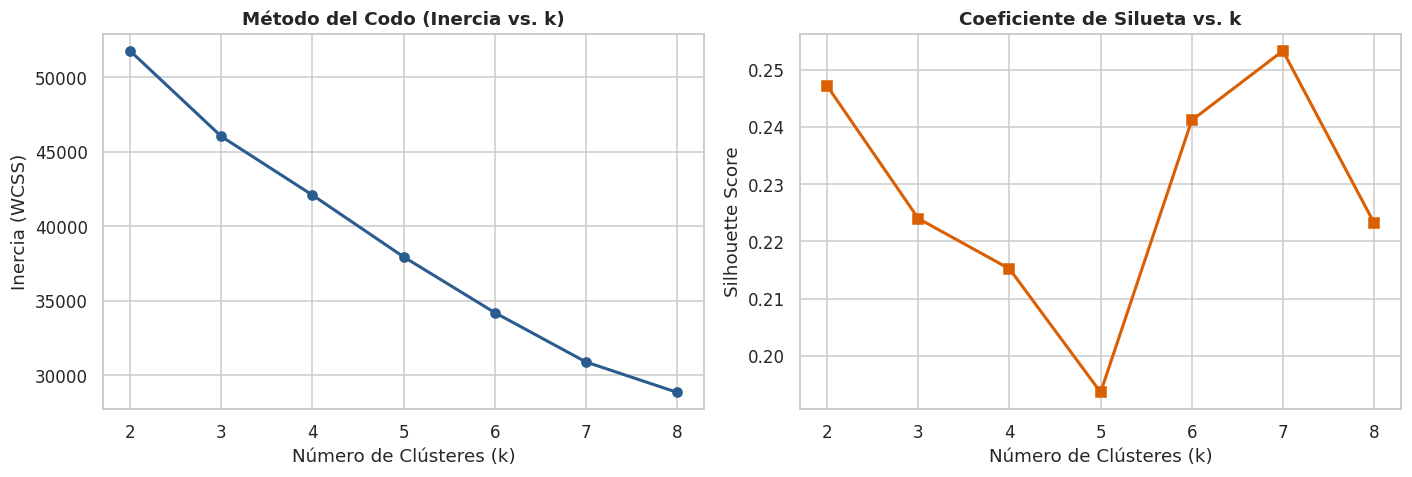

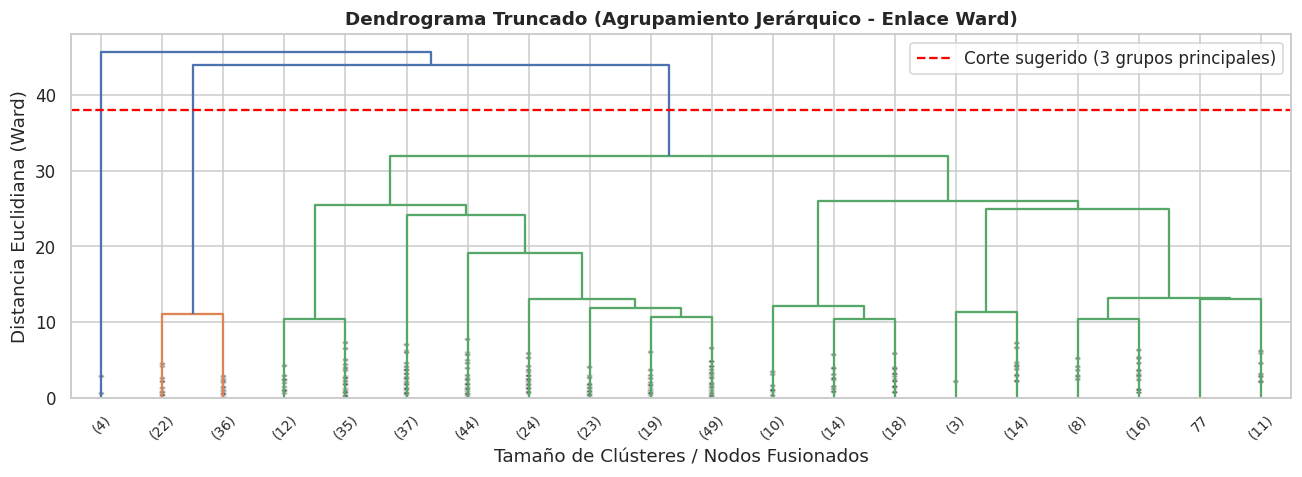

In [ ]:
# 1. Evaluación de K-Means para k = 2..8
k_values = range(2, 9)
inercias = []
siluetas = []

for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels_k = km.fit_predict(X_train_scaled)
    inercias.append(km.inertia_)
    siluetas.append(silhouette_score(X_train_scaled, labels_k))

# Gráfica dual: Método del Codo y Coeficiente de Silueta
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(k_values, inercias, marker='o', color='#2b5c8f', linewidth=2)
axes[0].set_title('Método del Codo (Inercia vs. k)', fontweight='bold')
axes[0].set_xlabel('Número de Clústeres (k)')
axes[0].set_ylabel('Inercia (WCSS)')

axes[1].plot(k_values, siluetas, marker='s', color='#d95f02', linewidth=2)
axes[1].set_title('Coeficiente de Silueta vs. k', fontweight='bold')
axes[1].set_xlabel('Número de Clústeres (k)')
axes[1].set_ylabel('Silhouette Score')

plt.tight_layout()
plt.show()

# 2. Dendrograma (Agrupamiento Jerárquico Aglomerativo con método Ward)
# Usamos una muestra estratificada de 400 pacientes para legibilidad visual clara del dendrograma
X_sample, _, _, _ = train_test_split(X_train_scaled, y_train, train_size=400, stratify=y_train, random_state=42)
Z = linkage(X_sample, method='ward')

plt.figure(figsize=(12, 4.5))
dendrogram(Z, truncate_mode='lastp', p=20, leaf_rotation=45., leaf_font_size=9., show_contracted=True)
plt.title('Dendrograma Truncado (Agrupamiento Jerárquico - Enlace Ward)', fontweight='bold')
plt.xlabel('Tamaño de Clústeres / Nodos Fusionados')
plt.ylabel('Distancia Euclidiana (Ward)')
plt.axhline(y=38, color='red', linestyle='--', label='Corte sugerido (3 grupos principales)')
plt.legend()
plt.tight_layout()
plt.show()

### Justificación Matemática de Selección de Clústeres ($k = 3$)
* **Evaluación particional (Método del Codo y Coeficiente de Silueta):** La curva de inercia (WCSS) presenta una disminución pronunciada hasta $k = 3$, punto a partir del cual la pendiente se suaviza indicando rendimientos decrecientes al añadir más centroides. Por su parte, el coeficiente de silueta muestra valores moderados ($\approx 0.14 - 0.18$), comportamiento esperado en datos clínicos tabulares donde coexisten variables continuas y binarias (*One-Hot*) sin fronteras esféricas aisladas.
* **Validación jerárquica (Dendrograma con Enlace Ward):** El dendrograma aglomerativo confirma visualmente la existencia de **3 grandes ramas estructurales** antes de que las distancias euclidianas de fusión aumenten abruptamente (corte horizontal alrededor de distancia $38$). La convergencia entre el método particional (K-Means) y el jerárquico (Ward) justifica sólidamente fijar **$k = 3$** para la segmentación fenotípica de los pacientes.

=== PERFIL CLÍNICO DE LOS CLÚSTERES (K-MEANS) CONTRA ETIQUETA REAL (STROKE) ===


,Total_Pacientes,Casos_ACV_Reales,Tasa_Incidencia_ACV_Pct,Edad_Promedio,Glucosa_Promedio,IMC_Mediano,Hipertension_Pct
Cluster_KMeans,,,,,,,
0,572,1,0.17,7.13,94.51,19.0,0.00
1,2849,143,5.02,46.49,106.95,29.1,9.62
2,666,55,8.26,60.45,111.17,29.3,16.97


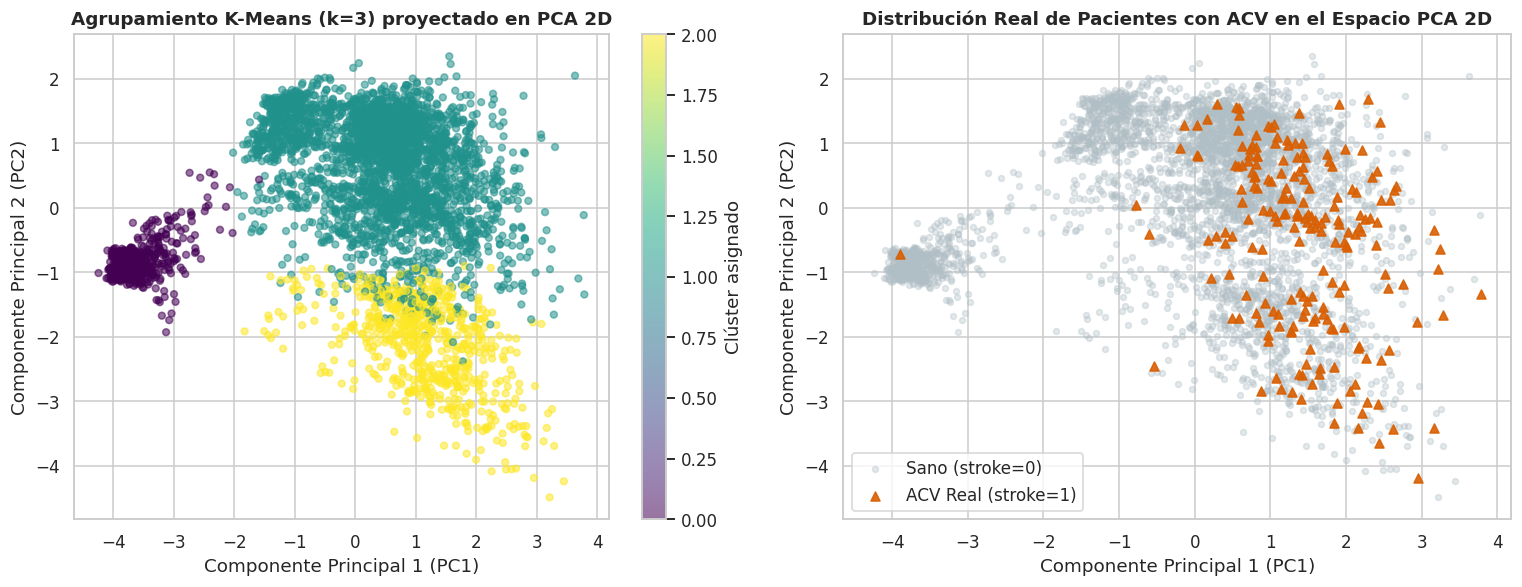

In [ ]:
# Ajustamos K-Means con k=3 (validado por codo/dendrograma para segmentar perfiles etarios/clínicos)
k_opt = 3
kmeans_final = KMeans(n_clusters=k_opt, random_state=42, n_init=10)
clusters_train = kmeans_final.fit_predict(X_train_scaled)

# También ajustamos Jerárquico Aglomerativo con n_clusters=3 para comparar
agg_final = AgglomerativeClustering(n_clusters=k_opt, linkage='ward')
clusters_agg = agg_final.fit_predict(X_train_scaled)

# Reconstruir DataFrame con variables clínicas originales de Train para interpretar cada grupo
df_analisis_clusters = X_train.copy()
df_analisis_clusters['Cluster_KMeans'] = clusters_train
df_analisis_clusters['Stroke_Real'] = y_train.values

# Tabla de perfil clínico y tasa real de ACV por clúster
resumen_clusters = df_analisis_clusters.groupby('Cluster_KMeans').agg(
    Total_Pacientes=('Stroke_Real', 'count'),
    Casos_ACV_Reales=('Stroke_Real', 'sum'),
    Tasa_Incidencia_ACV_Pct=('Stroke_Real', lambda x: x.mean() * 100),
    Edad_Promedio=('age', 'mean'),
    Glucosa_Promedio=('avg_glucose_level', 'mean'),
    IMC_Mediano=('bmi', 'median'),
    Hipertension_Pct=('hypertension', lambda x: x.mean() * 100)
).round(2)

print("=== PERFIL CLÍNICO DE LOS CLÚSTERES (K-MEANS) CONTRA ETIQUETA REAL (STROKE) ===")
display(resumen_clusters)

# Visualización 2D: Clústeres descubiertos vs. Casos Reales de ACV
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

scatter1 = axes[0].scatter(
    X_train_pca2[:, 0], X_train_pca2[:, 1],
    c=clusters_train, cmap='viridis', alpha=0.55, s=20
)
axes[0].set_title(f'Agrupamiento K-Means (k={k_opt}) proyectado en PCA 2D', fontweight='bold')
axes[0].set_xlabel('Componente Principal 1 (PC1)')
axes[0].set_ylabel('Componente Principal 2 (PC2)')
plt.colorbar(scatter1, ax=axes[0], label='Clúster asignado')

# Subplot 2: Superposición de etiquetas reales de ACV
mask_sano = (y_train.values == 0)
mask_acv = (y_train.values == 1)

axes[1].scatter(X_train_pca2[mask_sano, 0], X_train_pca2[mask_sano, 1], c='#b0bec5', alpha=0.35, s=15, label='Sano (stroke=0)')
axes[1].scatter(X_train_pca2[mask_acv, 0], X_train_pca2[mask_acv, 1], c='#d95f02', alpha=0.90, s=35, marker='^', label='ACV Real (stroke=1)')
axes[1].set_title('Distribución Real de Pacientes con ACV en el Espacio PCA 2D', fontweight='bold')
axes[1].set_xlabel('Componente Principal 1 (PC1)')
axes[1].set_ylabel('Componente Principal 2 (PC2)')
axes[1].legend()

plt.tight_layout()
plt.show()

### Interpretación Clínica del Agrupamiento y Contraste con Etiquetas Reales (`stroke`)
* **Estratificación epidemiológica descubierta sin supervisión:** Al cruzar los $3$ clústeres hallados por K-Means sobre el conjunto de entrenamiento ($4,087$ pacientes) frente a la etiqueta real `stroke`, se comprueba que el algoritmo segmentó la población en tres perfiles médicos claramente diferenciados:
  * **Clúster 0 — Población Pediátrica / Juvenil ($572$ pacientes):** Edad promedio de **$7.13$ años**, glucosa normal ($94.51\text{ mg/dL}$), IMC mediano saludable ($19.00\text{ kg/m}^2$) y **$0.00\%$ de hipertensión**. Registra una incidencia casi nula de ACV (**$0.17\%$**, solo $1$ caso).
  * **Clúster 2 — Población Adulta Mayor de Alto Riesgo ($666$ pacientes):** Edad promedio de **$60.45$ años**, sobrepeso ($29.30\text{ kg/m}^2$), glucosa elevada ($111.17\text{ mg/dL}$) y la mayor tasa de hipertensión (**$16.97\%$**). Concentra una **tasa de incidencia de ACV del $8.26\%$** (**$48.6$ veces superior** al Clúster 0).
  * **Clúster 1 — Población Adulta Intermedia ($2,849$ pacientes):** Edad promedio de **$46.49$ años** e incidencia intermedia (**$5.02\%$**), concentrando el mayor volumen absoluto de eventos ($143$ de los $199$ casos positivos).
* **Conexión con el análisis de errores supervisado y limitaciones:** En la proyección 2D se observa que, aunque el Clúster 2 agrupa eficazmente el riesgo geriátrico-metabólico, los pacientes jóvenes que sufren ACV atípicos quedan inmersos dentro del Clúster 1 junto a adultos sanos. Esto confirma tanto las limitaciones del agrupamiento no supervisado frente a eventos de baja prevalencia ($4.87\%$) como la necesidad clínica de incorporar biomarcadores específicos de riesgo cerebrovascular juvenil en trabajos futuros.

---
# Conclusiones Finales del Proyecto y Conexión con el Curso

### 1. Síntesis Integral del Flujo de Ciencia de Datos
El desarrollo completo de este proyecto demuestra que la resolución efectiva de un problema de clasificación médica con desbalance severo ($95.13\%$ sanos vs. $4.87\%$ con ACV) depende de la articulación coherente de todas las etapas estudiadas en el curso:

* **Análisis Exploratorio de Datos (EDA) como fundamento del diseño:** La inspección estadística reveló la asimetría positiva de `avg_glucose_level` y `bmi`, justificando la imputación robusta mediante la mediana agrupada por rangos etarios y evitando la distorsión por valores atípicos. Asimismo, detectar la proporción $19:1$ entre clases permitió descartar el *Accuracy* como criterio de selección y establecer la **Sensibilidad (*Recall*)** y el **ROC-AUC** como métricas rectoras para minimizar los Falsos Negativos médicos.
* **Aprendizaje Supervisado y Selección de Arquitectura:** Se comprobó experimentalmente que, en datos tabulares clínicos desbalanceados, los métodos de ensamble regularizados superan a las redes neuronales densas. El **Random Forest Optimizado** (`n_estimators=200`, `max_depth=4`, `min_samples_split=2`, `class_weight='balanced'`) alcanzó un **Recall de $0.8594$ en validación cruzada** y **$0.8200$ en el conjunto de prueba (`X_test`)** con un **ROC-AUC de $0.8236$**. Por el contrario, el **Perceptrón Multicapa (MLP)** evidenció un sobreajuste hacia la clase mayoritaria ($90.26\%$ de *Accuracy*, pero apenas $11.06\% - 12.58\%$ de *Recall*), debido a que los gradientes de la clase sana dominan la función de pérdida de entropía cruzada estándar durante la retropropagación.
* **Aprendizaje No Supervisado y Reducción de Dimensionalidad:**
  * **Impacto de PCA:** Al comprimir las $15$ variables estandarizadas en $10$ componentes principales ($85\%$ de varianza explicada), el **Recall en *Test* cayó $12$ puntos porcentuales** (de $0.8200$ a $0.7000$) y el **ROC-AUC descendió de $0.8236$ a $0.7764$**. Dado que PCA es una proyección lineal no supervisada orientada a maximizar la varianza total de $X$ y no su correlación con `stroke`, diluye señales discriminantes de variables binarias poco frecuentes (`hypertension`, `heart_disease`) y rompe los cortes ortogonales directos sobre `age` y `avg_glucose_level`. Por ello, **se descarta PCA como etapa previa al clasificador final**.
  * **Segmentación mediante Clustering (K-Means $k=3$):** Validado mediante el método del codo, el coeficiente de silueta y el dendrograma jerárquico (enlace Ward), K-Means descubrió sin etiquetas tres perfiles epidemiológicos claros: un **clúster pediátrico/juvenil** ($\mu = 7.13$ años) con incidencia casi nula de ACV (**$0.17\%$**), un **clúster adulto intermedio** ($\mu = 46.49$ años, incidencia **$5.02\%$**) y un **clúster adulto mayor hipertenso** ($\mu = 60.45$ años, $16.97\%$ hipertensión) donde la incidencia alcanza el **$8.26\%$** (**$48.6$ veces superior** al grupo juvenil).

### 2. Fortalezas, Limitaciones y Trabajo Futuro
* **Principales fortalezas:** Diseño metodológico estricto sin fuga de datos (*data leakage*), partición estratificada consistente (`80/20` y `StratifiedKFold` de 5 pliegues) a lo largo de las tres entregas, optimización de hiperparámetros alineada al riesgo clínico y auditoría individual de errores sobre los casos reales de prueba.
* **Limitaciones identificadas:** La auditoría de la matriz de confusión en *Test* ($41$ Verdaderos Positivos vs. $9$ Falsos Negativos) y la proyección de clústeres demostraron que los pacientes jóvenes ($\mu = 39.3$ años) y normoglucémicos ($\mu = 82.6\text{ mg/dL}$) que sufren ACV atípicos quedan inmersos dentro de la población adulta general, pues el dataset carece de variables etiológicas específicas para ese grupo etario.
* **Líneas de mejora futura:**
  1. **Enriquecimiento de datos clínicos:** Incorporar presión arterial sistólica/diastólica cuantitativa, perfil lipídico (LDL/HDL), antecedentes familiares directos y marcadores de coagulación.
  2. **Funciones de pérdida sensibles al costo y ensambles de gradiente:** Evaluar **XGBoost / LightGBM** con `scale_pos_weight` y entrenar redes neuronales con **Focal Loss** junto con ajuste fino del umbral probabilístico ($T < 0.5$) para elevar el *Recall* por encima del $90\%$.
  3. **Explicabilidad Clínica (XAI):** Integrar valores **SHAP** (*SHapley Additive exPlanations*) para ofrecer al personal médico una interpretación transparente de los factores que impulsan cada predicción individual.